# Band noise ad ampiezze alte (-13, -12.5, -12) + baseline OFF

Dati da `Simulations_bandnoise_sv44_50comp.ipynb`: 50 componenti, gamma = 3, stesso seed per tutte, quindi stessa
realizzazione di red noise, DM e scattering. Cambia solo l ampiezza del band noise (OFF = band noise spento).

Per ogni ampiezza: analisi con il modello a 6 par (band noise non modellato) e con quello a 8 par (band noise nel modello).

In [6]:
import numpy as np
import os, glob, json
import pickle

import sys

# this is the path to the discovery folder
sys.path.insert(0, "./")
import discovery_new as ds

import matplotlib.pyplot as plt
import scipy
import jax.numpy as jnp

from scipy.stats import uniform
import re
from PTMCMCSampler.PTMCMCSampler import PTSampler as ptmcmc
from scipy.stats import uniform
import jax

import time
import emcee
import corner

Optional mpi4py package is not installed.  MPI support is not available.


In [7]:
# path to the folder with the data
path = './dati/DR2low_feathers/'
s_dsfiles = np.sort(os.listdir(path))
psr = [ds.pulsar.Pulsar.read_feather(path + f'{psrfile}') for psrfile in s_dsfiles][9] # we are only analysing pulsar #9

In [8]:
# data
model = [psr.residuals]
# timing model
model += [ds.makegp_timing(psr, svd=True)]
# white noise parameters
model += [ds.makenoise_measurement(psr, psr.noisedict, tnequad = True, ecorr=True)]
# red noise paramters
model.append(ds.makegp_fourier(psr, ds.powerlaw, psr.noisedict[psr.name + '_red_components'], T=ds.getspan(psr), name='red_noise' ))
# DM variation parameters
model.append(ds.makegp_fourier(psr, ds.powerlaw, psr.noisedict[psr.name + '_dm_components'], T=ds.getspan(psr), name='dm_gp', fourierbasis=ds.make_dmfourierbasis(alpha = 2.0, tndm = False)))
# scattering noise parameters
model.append(ds.makegp_fourier(psr, ds.powerlaw, psr.noisedict[psr.name + '_chrom_components'], T=ds.getspan(psr), name='sv_gp', fourierbasis=ds.make_dmfourierbasis(alpha = 4.0, tndm = False)))

In [9]:
logL = ds.PulsarLikelihood(model).logL

In [10]:
##### Cell for the prior distributions ###################################################################################

my_priordict = {}
my_priordict["(.*_)?sv_gp_gamma.*"] = [0, 7]
my_priordict["(.*_)?sv_gp_alpha.*"] = [0, 10]
my_priordict["(.*_)?sv_gp_log10_A.*"] = [-20, -11]
my_priordict["(.*_)?sw_log10_A.*"] = [-10, 1]
my_priordict["(.*_)?sw_gamma.*"] = [-5, 6]
my_priordict["(.*_)?dm_gp_gamma.*"] = [0, 7]
my_priordict["(.*_)?dm_gp_log10_A.*"] = [-20, -11]
my_priordict["(.*_)?red_noise_gamma.*"] = [0, 7]
my_priordict["(.*_)?red_noise_log10_A.*"] = [-20, -11]
my_priordict["(.*_)?sw_n_earth.*"] = [0, 30]
# band noise: stesse prior degli altri processi power-law
my_priordict["(.*_)?band_noise_gamma.*"] = [0, 7]
my_priordict["(.*_)?band_noise_log10_A.*"] = [-20, -11]


def build_priors(param_names, priordict):
    """
    Build a {param_name: scipy dist} dict with uniform prior distributions in the range
    """
    priors = {}
    unmatched = []
    for name in param_names:
        matched = False
        for pattern, (lo, hi) in priordict.items():
            if re.fullmatch(pattern, name):
                priors[name] = uniform(loc=lo, scale=hi - lo)
                matched = True
                break
        if not matched:
            unmatched.append(name)

    if unmatched:
        print(f"Warning: no prior found for {len(unmatched)} parameters, "
              f"falling back to standard normal:\n  {unmatched}")
    return priors

## OFF: baseline, band noise spento

In [6]:
off_psr = ds.pulsar.Pulsar.read_feather('sim_data_noise_bn_OFF_sv44_50componenti/J1640+2224')   # band noise a -30, cioe spento
print('nome     :', off_psr.name)
print('N_TOA    :', len(off_psr.toas))
print('shape M  :', off_psr.Mmat.shape)

nome     : J1640+2224
N_TOA    : 6777
shape M  : (6777, 39)


In [7]:
# modello a 6 par: quello standard, senza band noise
model_off = [off_psr.residuals]
model_off += [ds.makegp_timing(off_psr, svd=True)]
model_off += [ds.makenoise_measurement(off_psr, off_psr.noisedict, tnequad=True, ecorr=True)]
model_off.append(ds.makegp_fourier(off_psr, ds.powerlaw, off_psr.noisedict[off_psr.name + '_red_components'],
                                 T=ds.getspan(off_psr), name='red_noise'))
model_off.append(ds.makegp_fourier(off_psr, ds.powerlaw, off_psr.noisedict[off_psr.name + '_dm_components'],
                                 T=ds.getspan(off_psr), name='dm_gp',
                                 fourierbasis=ds.make_dmfourierbasis(alpha=2.0, tndm=False)))
model_off.append(ds.makegp_fourier(off_psr, ds.powerlaw, off_psr.noisedict[off_psr.name + '_chrom_components'],
                                 T=ds.getspan(off_psr), name='sv_gp',
                                 fourierbasis=ds.make_dmfourierbasis(alpha=4.4, tndm=False)))

logL_off = ds.PulsarLikelihood(model_off).logL
logL_off.params

['J1640+2224_dm_gp_gamma',
 'J1640+2224_dm_gp_log10_A',
 'J1640+2224_red_noise_gamma',
 'J1640+2224_red_noise_log10_A',
 'J1640+2224_sv_gp_gamma',
 'J1640+2224_sv_gp_log10_A']

In [8]:
def params_dict_from_array_off(x):
    x = np.asarray(x)
    return dict(zip(logL_off.params, x))

priors_off = build_priors(logL_off.params, my_priordict)

def log_prior_off(x):
    params = params_dict_from_array_off(x)
    logp = 0.0
    for name, value in params.items():
        if name in priors_off:
            logp += priors_off[name].logpdf(value)
        else:
            logp += -0.5 * np.sum(np.asarray(value)**2)
    return logp

def prior_draw_off():
    return np.array([priors_off[name].rvs() for name in logL_off.params])

x0_off = prior_draw_off()

In [9]:
@jax.jit
def _jit_logL_off(params_array):
    return logL_off(dict(zip(logL_off.params, params_array)))

def log_likelihood_off(x):
    x = np.asarray(x, dtype=np.float64)
    return float(np.array(_jit_logL_off(jnp.array(x))))

print('logL iniziale =', log_likelihood_off(x0_off))

logL iniziale = 67837.4890496061


In [10]:
sampler_off = ptmcmc(
    ndim=len(logL_off.params),
    logl=log_likelihood_off,
    logp=log_prior_off,
    cov=np.eye(len(logL_off.params)) * 0.001,
    outDir='./test_sim_bn_OFF_50comp/',
    resume=True
)

In [11]:
ESEGUI_SAMPLING_OFF = False   # True solo per lanciare davvero il campionamento

if ESEGUI_SAMPLING_OFF:
    print("Starting sampling (baseline OFF, modello a 6 par)...")
    sampler_off.sample(x0_off, Niter=1000000, thin=10)

Starting sampling (baseline OFF, modello a 6 par)...
Finished 1.00 percent (1.00 percent of new work) in 14.875723 s Acceptance rate = 0.2227Adding DE jump with weight 20
Finished 100.00 percent (100.00 percent of new work) in 1691.387882 s Acceptance rate = 0.26205
Run Complete


In [51]:
chain_off = np.loadtxt('./test_sim_bn_OFF_50comp/chain_1.txt')[:, :-4]
chain_off = chain_off[len(chain_off)//4:]
chain_off.shape

(75001, 6)

In [52]:
tau_off = emcee.autocorr.integrated_time(chain_off, has_walkers=False, quiet=True)
print('tau:', tau_off)
print('Effective length =', int(len(chain_off) / tau_off.max()))

tau: [5.44174665 5.42894178 7.60402531 2.93081599 5.94997572 4.49034864]
Effective length = 9863


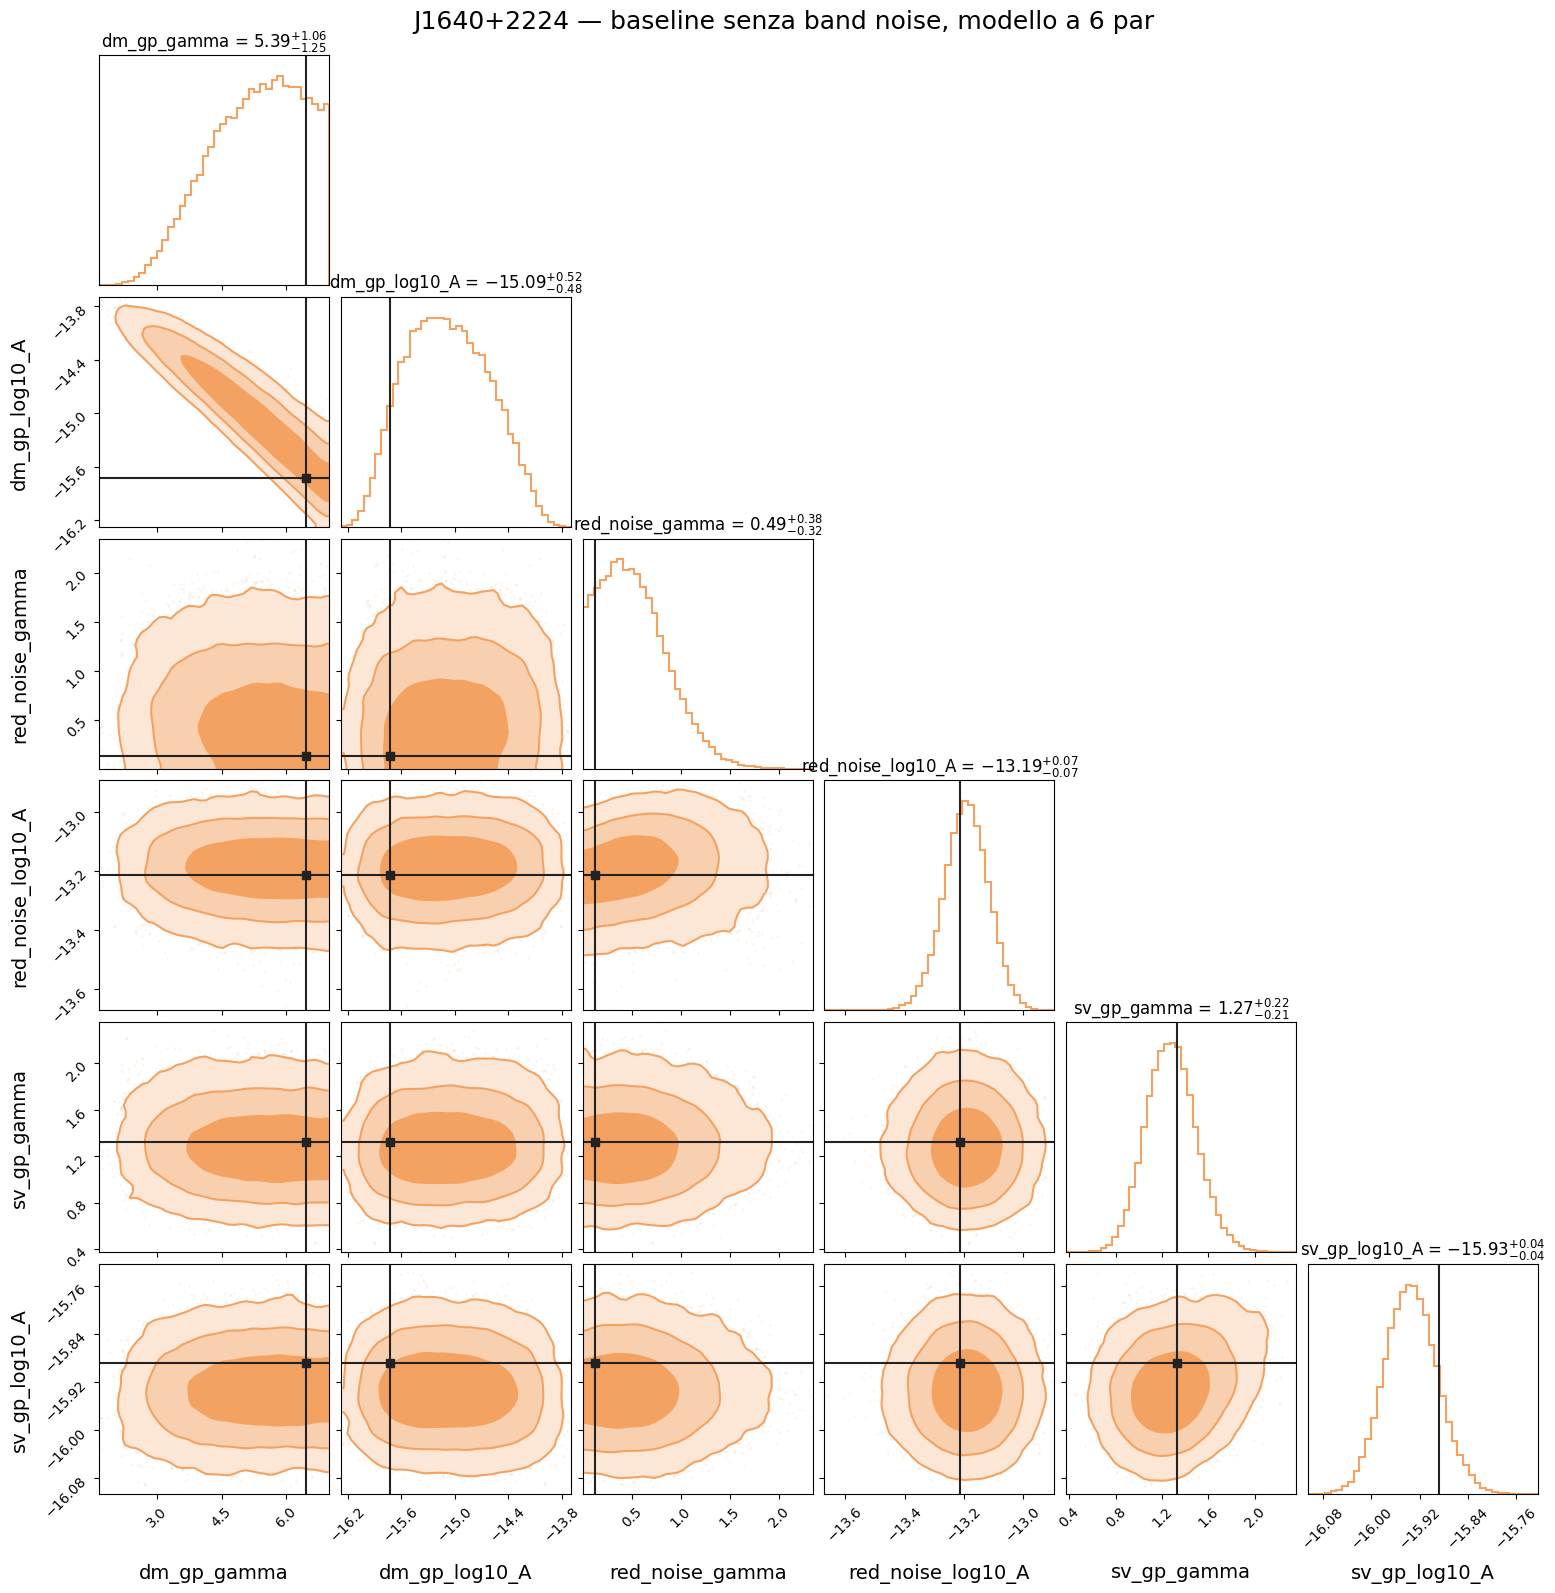

In [14]:
truths_dict = {
    'J1640+2224_dm_gp_gamma': 6.471070651479037,
    'J1640+2224_dm_gp_log10_A': -15.7227863246785,
    'J1640+2224_red_noise_gamma': 0.13235259553929019,
    'J1640+2224_red_noise_log10_A': -13.212902548624186,
    'J1640+2224_sv_gp_gamma': 1.3259815720503758,
    'J1640+2224_sv_gp_log10_A': -15.888300265911965,
}
truth_values = [truths_dict[p] for p in logL_off.params]
clean_labels = [name.replace('J1640+2224_', '') for name in logL_off.params]

fig = corner.corner(
    chain_off[:],
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color='#F4A261',
    hist_kwargs={'color': '#F4A261', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — baseline senza band noise, modello a 6 par',
             fontsize=18, y=1.00)

fig.savefig('corner_sim_bn_OFF_6par.png', dpi=150, bbox_inches='tight')

## A130: band noise a log10_A = -13.0

In [15]:
bn130_psr = ds.pulsar.Pulsar.read_feather('sim_data_noise_bn_A130_sv44_50componenti/J1640+2224')   # band noise a -13.0
print('nome     :', bn130_psr.name)
print('N_TOA    :', len(bn130_psr.toas))
print('shape M  :', bn130_psr.Mmat.shape)

nome     : J1640+2224
N_TOA    : 6777
shape M  : (6777, 39)


### A130, modello a 6 par

In [16]:
# modello a 6 par: quello standard, senza band noise
model_bn130_6par = [bn130_psr.residuals]
model_bn130_6par += [ds.makegp_timing(bn130_psr, svd=True)]
model_bn130_6par += [ds.makenoise_measurement(bn130_psr, bn130_psr.noisedict, tnequad=True, ecorr=True)]
model_bn130_6par.append(ds.makegp_fourier(bn130_psr, ds.powerlaw, bn130_psr.noisedict[bn130_psr.name + '_red_components'],
                                 T=ds.getspan(bn130_psr), name='red_noise'))
model_bn130_6par.append(ds.makegp_fourier(bn130_psr, ds.powerlaw, bn130_psr.noisedict[bn130_psr.name + '_dm_components'],
                                 T=ds.getspan(bn130_psr), name='dm_gp',
                                 fourierbasis=ds.make_dmfourierbasis(alpha=2.0, tndm=False)))
model_bn130_6par.append(ds.makegp_fourier(bn130_psr, ds.powerlaw, bn130_psr.noisedict[bn130_psr.name + '_chrom_components'],
                                 T=ds.getspan(bn130_psr), name='sv_gp',
                                 fourierbasis=ds.make_dmfourierbasis(alpha=4.4, tndm=False)))

logL_bn130_6par = ds.PulsarLikelihood(model_bn130_6par).logL
logL_bn130_6par.params

['J1640+2224_dm_gp_gamma',
 'J1640+2224_dm_gp_log10_A',
 'J1640+2224_red_noise_gamma',
 'J1640+2224_red_noise_log10_A',
 'J1640+2224_sv_gp_gamma',
 'J1640+2224_sv_gp_log10_A']

In [17]:
def params_dict_from_array_bn130_6par(x):
    x = np.asarray(x)
    return dict(zip(logL_bn130_6par.params, x))

priors_bn130_6par = build_priors(logL_bn130_6par.params, my_priordict)

def log_prior_bn130_6par(x):
    params = params_dict_from_array_bn130_6par(x)
    logp = 0.0
    for name, value in params.items():
        if name in priors_bn130_6par:
            logp += priors_bn130_6par[name].logpdf(value)
        else:
            logp += -0.5 * np.sum(np.asarray(value)**2)
    return logp

def prior_draw_bn130_6par():
    return np.array([priors_bn130_6par[name].rvs() for name in logL_bn130_6par.params])

x0_bn130_6par = prior_draw_bn130_6par()

In [18]:
@jax.jit
def _jit_logL_bn130_6par(params_array):
    return logL_bn130_6par(dict(zip(logL_bn130_6par.params, params_array)))

def log_likelihood_bn130_6par(x):
    x = np.asarray(x, dtype=np.float64)
    return float(np.array(_jit_logL_bn130_6par(jnp.array(x))))

print('logL iniziale =', log_likelihood_bn130_6par(x0_bn130_6par))

logL iniziale = 67393.3680315187


In [19]:
sampler_bn130_6par = ptmcmc(
    ndim=len(logL_bn130_6par.params),
    logl=log_likelihood_bn130_6par,
    logp=log_prior_bn130_6par,
    cov=np.eye(len(logL_bn130_6par.params)) * 0.001,
    outDir='./test_sim_bn_A130_50comp/',
    resume=True
)

In [20]:
ESEGUI_SAMPLING_OFF = False   # True solo per lanciare davvero il campionamento

if ESEGUI_SAMPLING_OFF:
    print("Starting sampling (band noise a -13.0, modello a 6 par)...")
    sampler_bn130_6par.sample(x0_bn130_6par, Niter=1000000, thin=10)

Starting sampling (band noise a -13.0, modello a 6 par)...
Finished 1.00 percent (1.00 percent of new work) in 18.475262 s Acceptance rate = 0.2166Adding DE jump with weight 20
Finished 100.00 percent (100.00 percent of new work) in 8193.450293 s Acceptance rate = 0.288934
Run Complete


In [21]:
chain_bn130_6par = np.loadtxt('./test_sim_bn_A130_50comp/chain_1.txt')[:, :-4]
chain_bn130_6par = chain_bn130_6par[len(chain_bn130_6par)//4:]
chain_bn130_6par.shape

(75001, 6)

In [22]:
tau_bn130_6par = emcee.autocorr.integrated_time(chain_bn130_6par, has_walkers=False, quiet=True)
print('tau:', tau_bn130_6par)
print('Effective length =', int(len(chain_bn130_6par) / tau_bn130_6par.max()))

tau: [5.73312519 5.76980481 7.16192124 2.71710016 4.93517996 4.62260605]
Effective length = 10472


### A130, modello a 8 par

In [23]:
# modello a 8 par: i 6 standard + band noise sui backend LOFAR
model_bn130_8par = [bn130_psr.residuals]
model_bn130_8par += [ds.makegp_timing(bn130_psr, svd=True)]
model_bn130_8par += [ds.makenoise_measurement(bn130_psr, bn130_psr.noisedict, tnequad=True, ecorr=True)]
model_bn130_8par.append(ds.makegp_fourier(bn130_psr, ds.powerlaw, bn130_psr.noisedict[bn130_psr.name + '_red_components'],
                                 T=ds.getspan(bn130_psr), name='red_noise'))
model_bn130_8par.append(ds.makegp_fourier(bn130_psr, ds.powerlaw, bn130_psr.noisedict[bn130_psr.name + '_dm_components'],
                                 T=ds.getspan(bn130_psr), name='dm_gp',
                                 fourierbasis=ds.make_dmfourierbasis(alpha=2.0, tndm=False)))
model_bn130_8par.append(ds.makegp_fourier(bn130_psr, ds.powerlaw, bn130_psr.noisedict[bn130_psr.name + '_chrom_components'],
                                 T=ds.getspan(bn130_psr), name='sv_gp',
                                 fourierbasis=ds.make_dmfourierbasis(alpha=4.4, tndm=False)))
model_bn130_8par.append(ds.makegp_fourier_select(bn130_psr, ds.powerlaw, components=50, T=ds.getspan(bn130_psr),
                                        name='band_noise', selection=ds.lofar_backends))

logL_bn130_8par = ds.PulsarLikelihood(model_bn130_8par).logL
logL_bn130_8par.params

['J1640+2224_band_noise_gamma',
 'J1640+2224_band_noise_log10_A',
 'J1640+2224_dm_gp_gamma',
 'J1640+2224_dm_gp_log10_A',
 'J1640+2224_red_noise_gamma',
 'J1640+2224_red_noise_log10_A',
 'J1640+2224_sv_gp_gamma',
 'J1640+2224_sv_gp_log10_A']

In [24]:
def params_dict_from_array_bn130_8par(x):
    x = np.asarray(x)
    return dict(zip(logL_bn130_8par.params, x))

priors_bn130_8par = build_priors(logL_bn130_8par.params, my_priordict)

def log_prior_bn130_8par(x):
    params = params_dict_from_array_bn130_8par(x)
    logp = 0.0
    for name, value in params.items():
        if name in priors_bn130_8par:
            logp += priors_bn130_8par[name].logpdf(value)
        else:
            logp += -0.5 * np.sum(np.asarray(value)**2)
    return logp

def prior_draw_bn130_8par():
    return np.array([priors_bn130_8par[name].rvs() for name in logL_bn130_8par.params])

x0_bn130_8par = prior_draw_bn130_8par()

In [25]:
@jax.jit
def _jit_logL_bn130_8par(params_array):
    return logL_bn130_8par(dict(zip(logL_bn130_8par.params, params_array)))

def log_likelihood_bn130_8par(x):
    x = np.asarray(x, dtype=np.float64)
    return float(np.array(_jit_logL_bn130_8par(jnp.array(x))))

print('logL iniziale =', log_likelihood_bn130_8par(x0_bn130_8par))

logL iniziale = 67053.5509060208


In [26]:
sampler_bn130_8par = ptmcmc(
    ndim=len(logL_bn130_8par.params),
    logl=log_likelihood_bn130_8par,
    logp=log_prior_bn130_8par,
    cov=np.eye(len(logL_bn130_8par.params)) * 0.001,
    outDir='./test_sim_bn_A130_bnmodel/',
    resume=True
)

In [27]:
ESEGUI_SAMPLING_OFF = False   # True solo per lanciare davvero il campionamento

if ESEGUI_SAMPLING_OFF:
    print("Starting sampling (band noise a -13.0, modello a 8 par)...")
    sampler_bn130_8par.sample(x0_bn130_8par, Niter=1000000, thin=10)

Starting sampling (band noise a -13.0, modello a 8 par)...
Finished 1.00 percent (1.00 percent of new work) in 23.096643 s Acceptance rate = 0.2187Adding DE jump with weight 20
Finished 100.00 percent (100.00 percent of new work) in 2170.149661 s Acceptance rate = 0.222791
Run Complete


In [28]:
chain_bn130_8par = np.loadtxt('./test_sim_bn_A130_bnmodel/chain_1.txt')[:, :-4]
chain_bn130_8par = chain_bn130_8par[len(chain_bn130_8par)//4:]
chain_bn130_8par.shape

(75001, 8)

In [29]:
tau_bn130_8par = emcee.autocorr.integrated_time(chain_bn130_8par, has_walkers=False, quiet=True)
print('tau:', tau_bn130_8par)
print('Effective length =', int(len(chain_bn130_8par) / tau_bn130_8par.max()))

tau: [12.65467774 13.84621508 12.63474388 12.84696597 11.19405213  3.24143366
 10.73204199  5.62610081]
Effective length = 5416


### A130, grafici

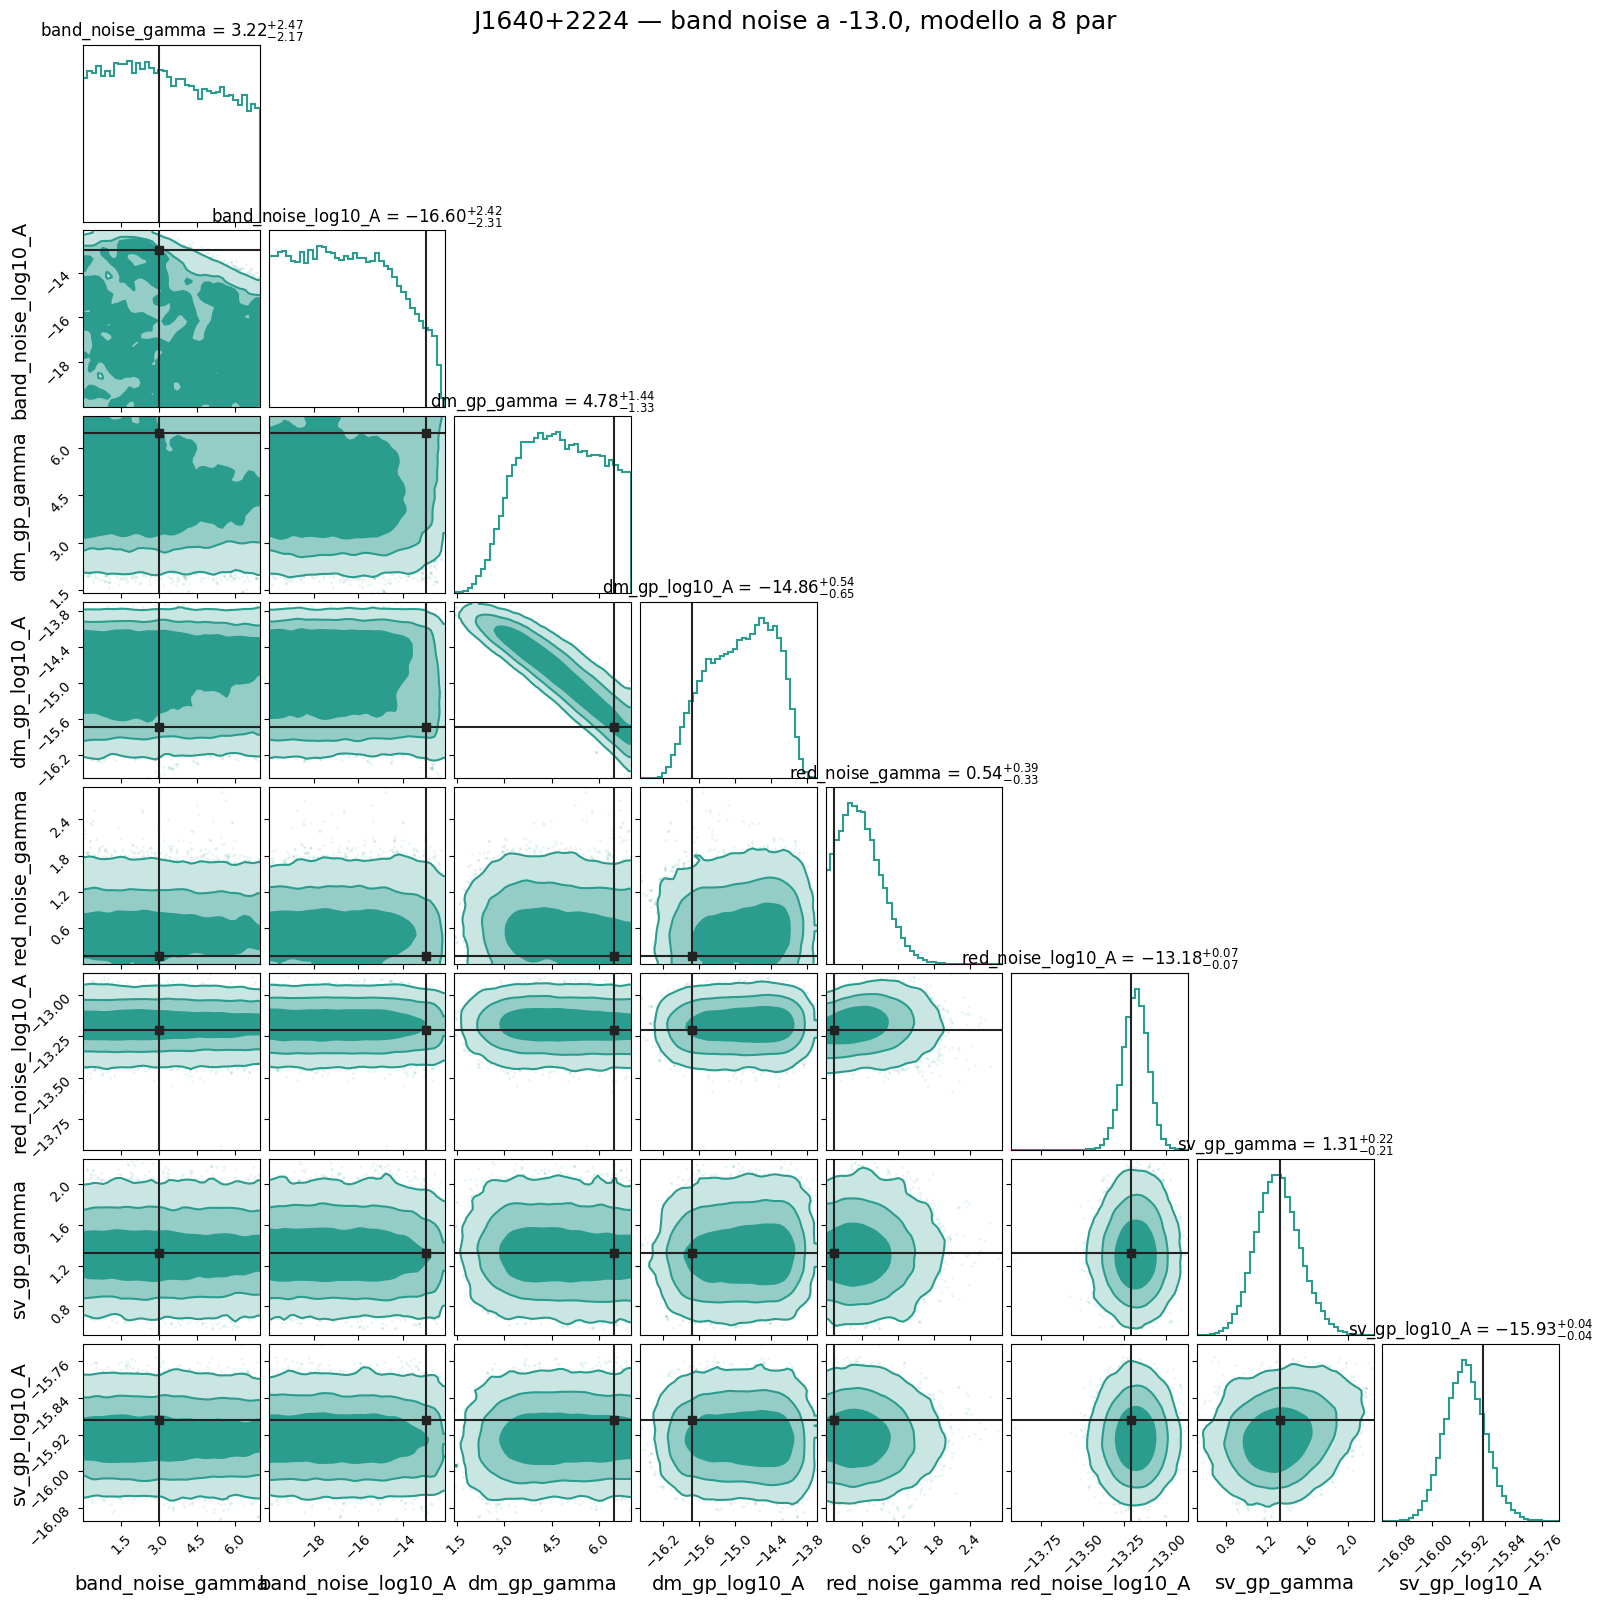

In [30]:
truths_dict = {
    'J1640+2224_dm_gp_gamma': 6.471070651479037,
    'J1640+2224_dm_gp_log10_A': -15.7227863246785,
    'J1640+2224_red_noise_gamma': 0.13235259553929019,
    'J1640+2224_red_noise_log10_A': -13.212902548624186,
    'J1640+2224_sv_gp_gamma': 1.3259815720503758,
    'J1640+2224_sv_gp_log10_A': -15.888300265911965,
    'J1640+2224_band_noise_gamma': 3.0,
    'J1640+2224_band_noise_log10_A': -13.0,
}
truth_values = [truths_dict[p] for p in logL_bn130_8par.params]
clean_labels = [name.replace('J1640+2224_', '') for name in logL_bn130_8par.params]

fig = corner.corner(
    chain_bn130_8par[:],
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color='#2A9D8F',
    hist_kwargs={'color': '#2A9D8F', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — band noise a -13.0, modello a 8 par',
             fontsize=18, y=1.00)

fig.savefig('corner_sim_bn_A130_bnmodel.png', dpi=150, bbox_inches='tight')

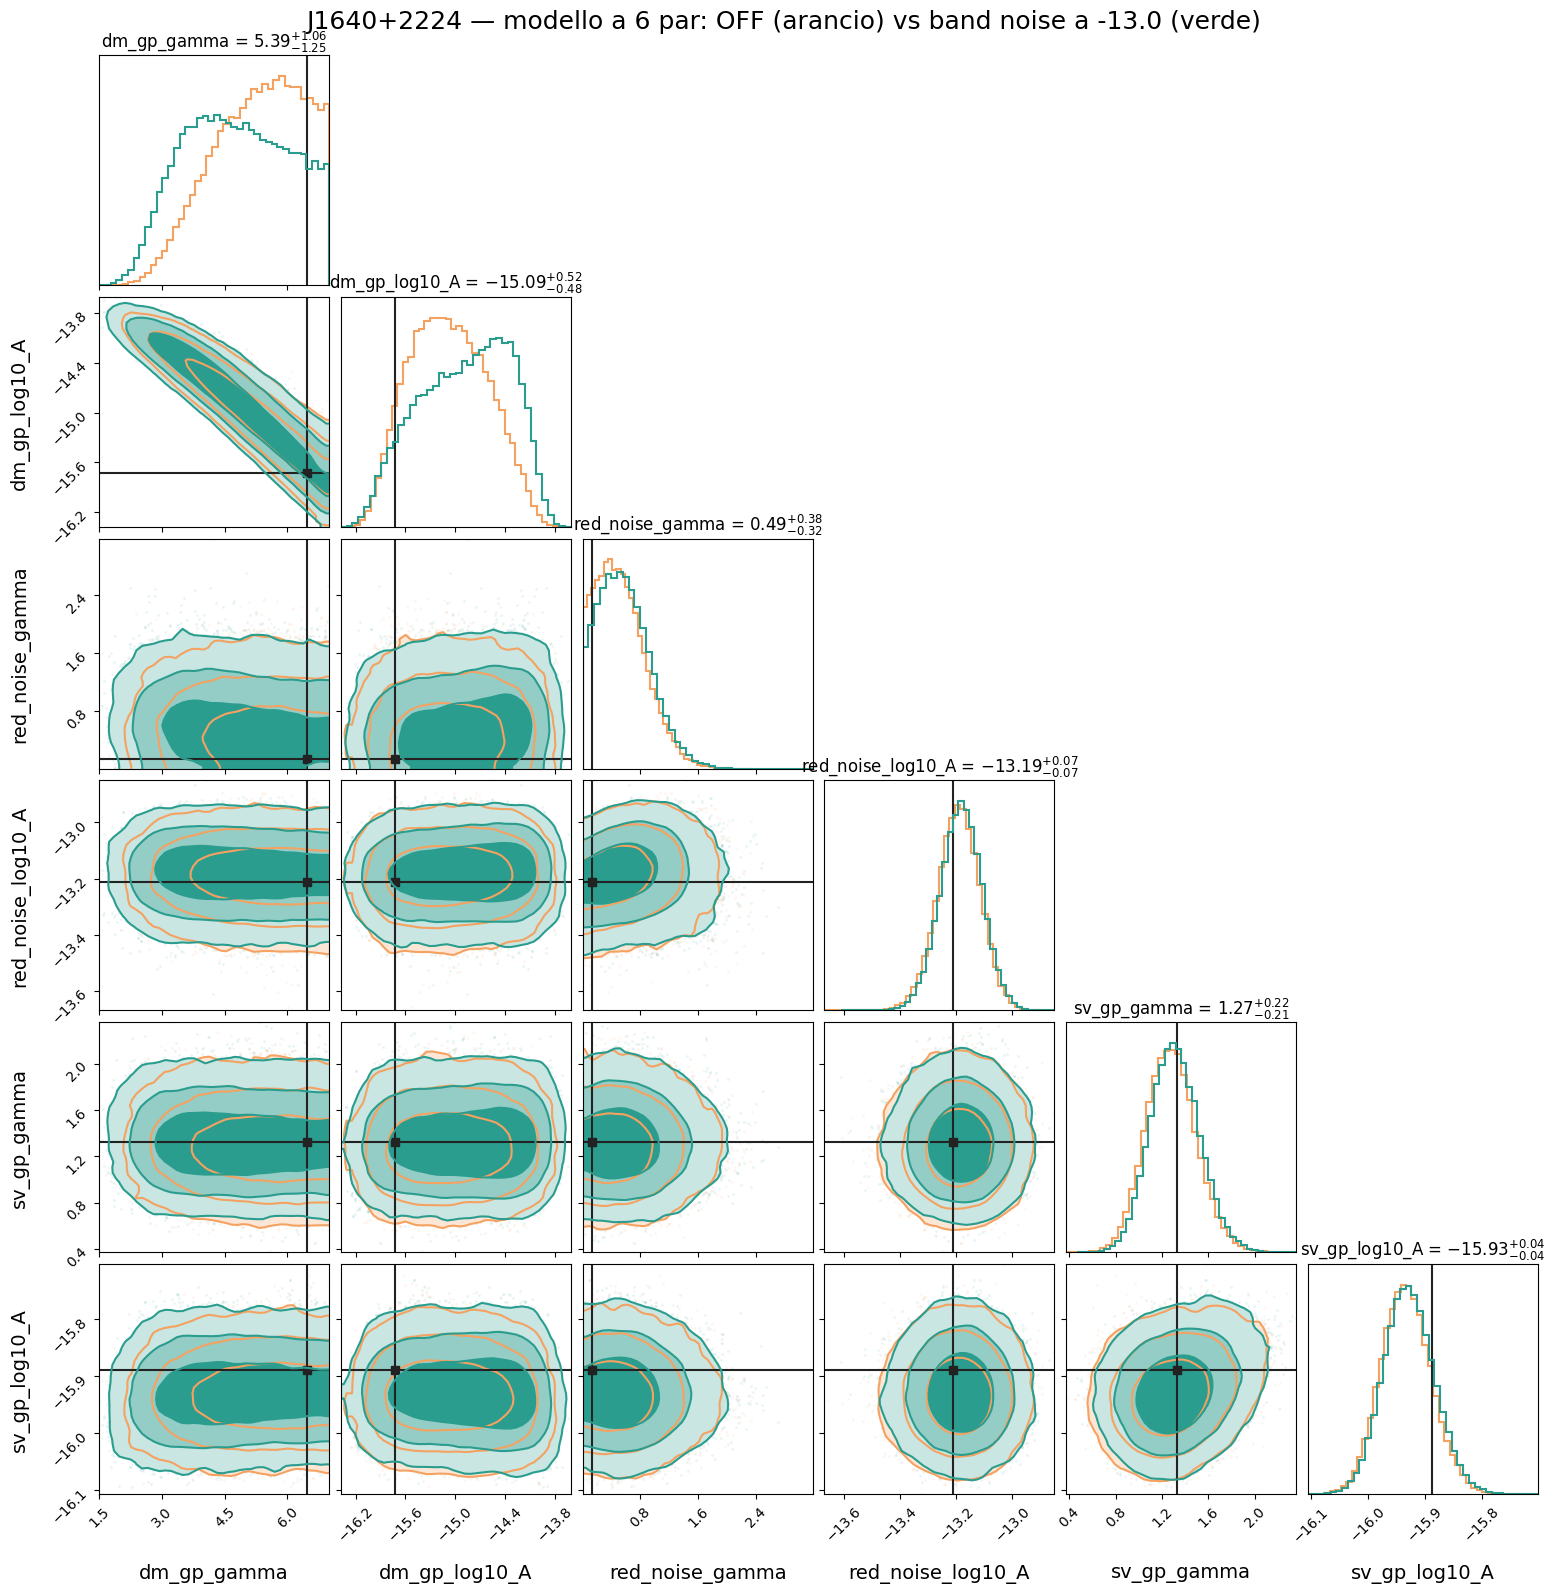

In [31]:
# stesso modello a 6 par, stessa realizzazione: cambia solo il band noise nei dati
truths_dict = {
    'J1640+2224_dm_gp_gamma': 6.471070651479037,
    'J1640+2224_dm_gp_log10_A': -15.7227863246785,
    'J1640+2224_red_noise_gamma': 0.13235259553929019,
    'J1640+2224_red_noise_log10_A': -13.212902548624186,
    'J1640+2224_sv_gp_gamma': 1.3259815720503758,
    'J1640+2224_sv_gp_log10_A': -15.888300265911965,
}
truth_values = [truths_dict[p] for p in logL_bn130_6par.params]
clean_labels = [name.replace('J1640+2224_', '') for name in logL_bn130_6par.params]

# Primo corner
fig = corner.corner(
    chain_off[:],
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color='#F4A261',
    hist_kwargs={'color': '#F4A261', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_bn130_6par[:],
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color='#2A9D8F',
    hist_kwargs={'color': '#2A9D8F', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — modello a 6 par: OFF (arancio) vs band noise a -13.0 (verde)',
             fontsize=18, y=1.00)

fig.savefig('corner_sim_bn_A130_6par_OFF_vs_con.png', dpi=150, bbox_inches='tight')

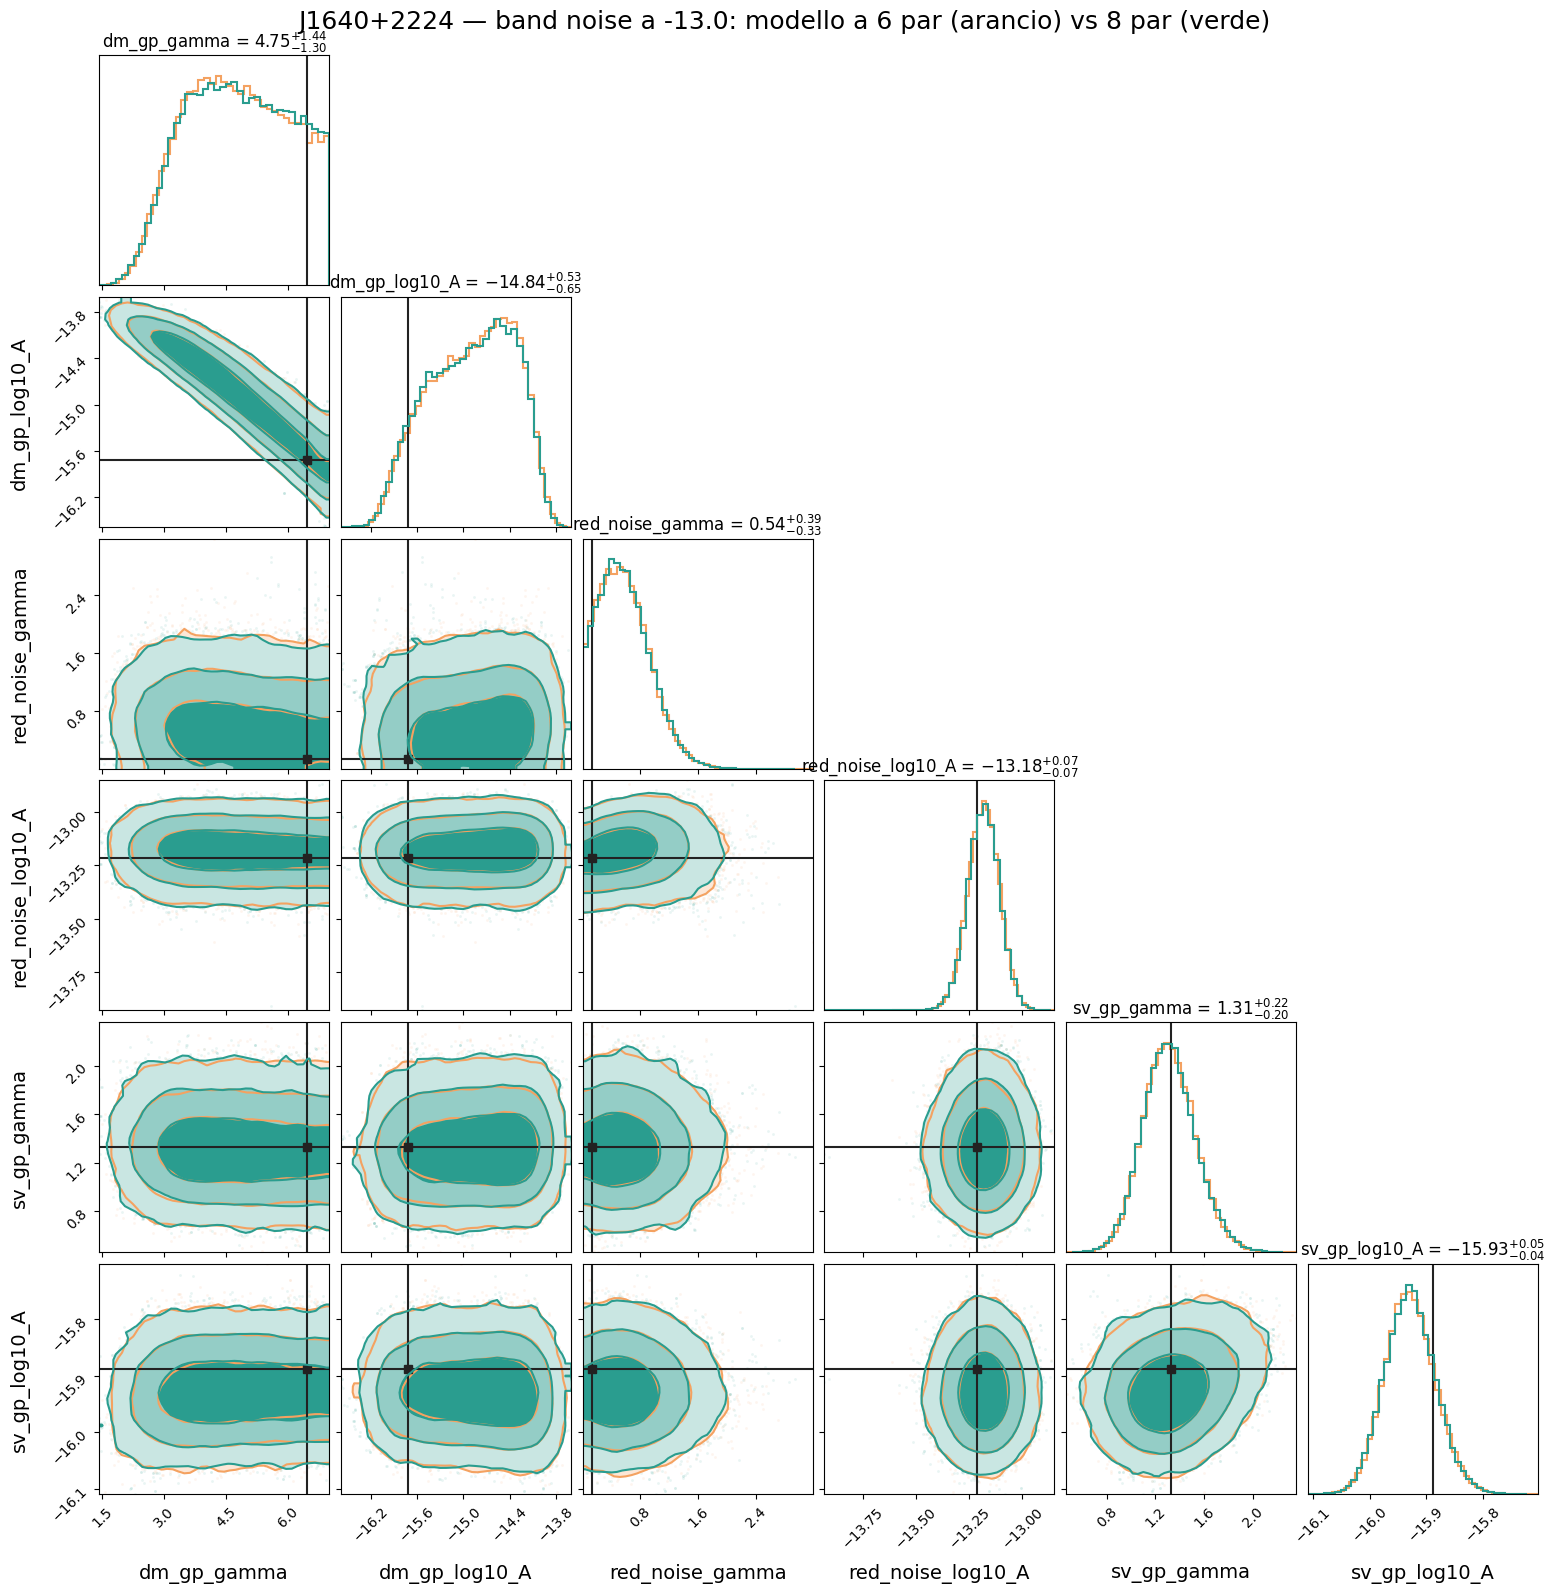

In [32]:
# dalla catena a 8 par tengo solo le 6 colonne comuni, nell ordine del modello a 6 par
chain_bn130_8par_comuni = chain_bn130_8par[:, [list(logL_bn130_8par.params).index(p) for p in logL_bn130_6par.params]]
truths_dict = {
    'J1640+2224_dm_gp_gamma': 6.471070651479037,
    'J1640+2224_dm_gp_log10_A': -15.7227863246785,
    'J1640+2224_red_noise_gamma': 0.13235259553929019,
    'J1640+2224_red_noise_log10_A': -13.212902548624186,
    'J1640+2224_sv_gp_gamma': 1.3259815720503758,
    'J1640+2224_sv_gp_log10_A': -15.888300265911965,
}
truth_values = [truths_dict[p] for p in logL_bn130_6par.params]
clean_labels = [name.replace('J1640+2224_', '') for name in logL_bn130_6par.params]

# Primo corner
fig = corner.corner(
    chain_bn130_6par[:],
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color='#F4A261',
    hist_kwargs={'color': '#F4A261', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_bn130_8par_comuni,
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color='#2A9D8F',
    hist_kwargs={'color': '#2A9D8F', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — band noise a -13.0: modello a 6 par (arancio) vs 8 par (verde)',
             fontsize=18, y=1.00)

fig.savefig('corner_sim_bn_A130_6par_vs_8par.png', dpi=150, bbox_inches='tight')

## A125: band noise a log10_A = -12.5

In [11]:
bn125_psr = ds.pulsar.Pulsar.read_feather('sim_data_noise_bn_A125_sv44_50componenti/J1640+2224')   # band noise a -12.5
print('nome     :', bn125_psr.name)
print('N_TOA    :', len(bn125_psr.toas))
print('shape M  :', bn125_psr.Mmat.shape)

nome     : J1640+2224
N_TOA    : 6777
shape M  : (6777, 39)


### A125, modello a 6 par

In [12]:
# modello a 6 par: quello standard, senza band noise
model_bn125_6par = [bn125_psr.residuals]
model_bn125_6par += [ds.makegp_timing(bn125_psr, svd=True)]
model_bn125_6par += [ds.makenoise_measurement(bn125_psr, bn125_psr.noisedict, tnequad=True, ecorr=True)]
model_bn125_6par.append(ds.makegp_fourier(bn125_psr, ds.powerlaw, bn125_psr.noisedict[bn125_psr.name + '_red_components'],
                                 T=ds.getspan(bn125_psr), name='red_noise'))
model_bn125_6par.append(ds.makegp_fourier(bn125_psr, ds.powerlaw, bn125_psr.noisedict[bn125_psr.name + '_dm_components'],
                                 T=ds.getspan(bn125_psr), name='dm_gp',
                                 fourierbasis=ds.make_dmfourierbasis(alpha=2.0, tndm=False)))
model_bn125_6par.append(ds.makegp_fourier(bn125_psr, ds.powerlaw, bn125_psr.noisedict[bn125_psr.name + '_chrom_components'],
                                 T=ds.getspan(bn125_psr), name='sv_gp',
                                 fourierbasis=ds.make_dmfourierbasis(alpha=4.4, tndm=False)))

logL_bn125_6par = ds.PulsarLikelihood(model_bn125_6par).logL
logL_bn125_6par.params

['J1640+2224_dm_gp_gamma',
 'J1640+2224_dm_gp_log10_A',
 'J1640+2224_red_noise_gamma',
 'J1640+2224_red_noise_log10_A',
 'J1640+2224_sv_gp_gamma',
 'J1640+2224_sv_gp_log10_A']

In [13]:
def params_dict_from_array_bn125_6par(x):
    x = np.asarray(x)
    return dict(zip(logL_bn125_6par.params, x))

priors_bn125_6par = build_priors(logL_bn125_6par.params, my_priordict)

def log_prior_bn125_6par(x):
    params = params_dict_from_array_bn125_6par(x)
    logp = 0.0
    for name, value in params.items():
        if name in priors_bn125_6par:
            logp += priors_bn125_6par[name].logpdf(value)
        else:
            logp += -0.5 * np.sum(np.asarray(value)**2)
    return logp

def prior_draw_bn125_6par():
    return np.array([priors_bn125_6par[name].rvs() for name in logL_bn125_6par.params])

x0_bn125_6par = prior_draw_bn125_6par()

In [14]:
@jax.jit
def _jit_logL_bn125_6par(params_array):
    return logL_bn125_6par(dict(zip(logL_bn125_6par.params, params_array)))

def log_likelihood_bn125_6par(x):
    x = np.asarray(x, dtype=np.float64)
    return float(np.array(_jit_logL_bn125_6par(jnp.array(x))))

print('logL iniziale =', log_likelihood_bn125_6par(x0_bn125_6par))

logL iniziale = 67958.65908613289


In [15]:
sampler_bn125_6par = ptmcmc(
    ndim=len(logL_bn125_6par.params),
    logl=log_likelihood_bn125_6par,
    logp=log_prior_bn125_6par,
    cov=np.eye(len(logL_bn125_6par.params)) * 0.001,
    outDir='./test_sim_bn_A125_50comp/',
    resume=True
)

In [17]:
ESEGUI_SAMPLING_OFF = True   # True solo per lanciare davvero il campionamento

if ESEGUI_SAMPLING_OFF:
    print("Starting sampling (band noise a -12.5, modello a 6 par)...")
    sampler_bn125_6par.sample(x0_bn125_6par, Niter=1000000, thin=10)

Starting sampling (band noise a -12.5, modello a 6 par)...
Finished 1.00 percent (1.00 percent of new work) in 18.048431 s Acceptance rate = 0.2742Adding DE jump with weight 20
Finished 100.00 percent (100.00 percent of new work) in 1789.638578 s Acceptance rate = 0.355155
Run Complete


In [18]:
chain_bn125_6par = np.loadtxt('./test_sim_bn_A125_50comp/chain_1.txt')[:, :-4]
chain_bn125_6par = chain_bn125_6par[len(chain_bn125_6par)//4:]
chain_bn125_6par.shape

(75001, 6)

In [19]:
tau_bn125_6par = emcee.autocorr.integrated_time(chain_bn125_6par, has_walkers=False, quiet=True)
print('tau:', tau_bn125_6par)
print('Effective length =', int(len(chain_bn125_6par) / tau_bn125_6par.max()))

tau: [5.76806064 9.48482156 4.63456678 4.19181694 3.90557738 1.94265628]
Effective length = 7907


### A125, modello a 8 par

In [20]:
# modello a 8 par: i 6 standard + band noise sui backend LOFAR
model_bn125_8par = [bn125_psr.residuals]
model_bn125_8par += [ds.makegp_timing(bn125_psr, svd=True)]
model_bn125_8par += [ds.makenoise_measurement(bn125_psr, bn125_psr.noisedict, tnequad=True, ecorr=True)]
model_bn125_8par.append(ds.makegp_fourier(bn125_psr, ds.powerlaw, bn125_psr.noisedict[bn125_psr.name + '_red_components'],
                                 T=ds.getspan(bn125_psr), name='red_noise'))
model_bn125_8par.append(ds.makegp_fourier(bn125_psr, ds.powerlaw, bn125_psr.noisedict[bn125_psr.name + '_dm_components'],
                                 T=ds.getspan(bn125_psr), name='dm_gp',
                                 fourierbasis=ds.make_dmfourierbasis(alpha=2.0, tndm=False)))
model_bn125_8par.append(ds.makegp_fourier(bn125_psr, ds.powerlaw, bn125_psr.noisedict[bn125_psr.name + '_chrom_components'],
                                 T=ds.getspan(bn125_psr), name='sv_gp',
                                 fourierbasis=ds.make_dmfourierbasis(alpha=4.4, tndm=False)))
model_bn125_8par.append(ds.makegp_fourier_select(bn125_psr, ds.powerlaw, components=50, T=ds.getspan(bn125_psr),
                                        name='band_noise', selection=ds.lofar_backends))

logL_bn125_8par = ds.PulsarLikelihood(model_bn125_8par).logL
logL_bn125_8par.params

['J1640+2224_band_noise_gamma',
 'J1640+2224_band_noise_log10_A',
 'J1640+2224_dm_gp_gamma',
 'J1640+2224_dm_gp_log10_A',
 'J1640+2224_red_noise_gamma',
 'J1640+2224_red_noise_log10_A',
 'J1640+2224_sv_gp_gamma',
 'J1640+2224_sv_gp_log10_A']

In [21]:
def params_dict_from_array_bn125_8par(x):
    x = np.asarray(x)
    return dict(zip(logL_bn125_8par.params, x))

priors_bn125_8par = build_priors(logL_bn125_8par.params, my_priordict)

def log_prior_bn125_8par(x):
    params = params_dict_from_array_bn125_8par(x)
    logp = 0.0
    for name, value in params.items():
        if name in priors_bn125_8par:
            logp += priors_bn125_8par[name].logpdf(value)
        else:
            logp += -0.5 * np.sum(np.asarray(value)**2)
    return logp

def prior_draw_bn125_8par():
    return np.array([priors_bn125_8par[name].rvs() for name in logL_bn125_8par.params])

x0_bn125_8par = prior_draw_bn125_8par()

In [22]:
@jax.jit
def _jit_logL_bn125_8par(params_array):
    return logL_bn125_8par(dict(zip(logL_bn125_8par.params, params_array)))

def log_likelihood_bn125_8par(x):
    x = np.asarray(x, dtype=np.float64)
    return float(np.array(_jit_logL_bn125_8par(jnp.array(x))))

print('logL iniziale =', log_likelihood_bn125_8par(x0_bn125_8par))

logL iniziale = 68030.09612370975


In [23]:
sampler_bn125_8par = ptmcmc(
    ndim=len(logL_bn125_8par.params),
    logl=log_likelihood_bn125_8par,
    logp=log_prior_bn125_8par,
    cov=np.eye(len(logL_bn125_8par.params)) * 0.001,
    outDir='./test_sim_bn_A125_bnmodel/',
    resume=True
)

In [26]:
print("Starting sampling (band noise a -12.5, modello a 8 par)...")
sampler_bn125_8par.sample(x0_bn125_8par, Niter=1000000, thin=10)

Starting sampling (band noise a -12.5, modello a 8 par)...
Resuming run from chain file ./test_sim_bn_A125_bnmodel//chain_1.txt
Resuming with 1101 samples from file representing 11001 original samples
Adding DE jump with weight 20
Finished 100.00 percent (100.00 percent of new work) in 3518.745415 s Acceptance rate = 0.315613
Run Complete


In [27]:
chain_bn125_8par = np.loadtxt('./test_sim_bn_A125_bnmodel/chain_1.txt')[:, :-4]
chain_bn125_8par = chain_bn125_8par[len(chain_bn125_8par)//4:]
chain_bn125_8par.shape

(75001, 8)

In [28]:
tau_bn125_8par = emcee.autocorr.integrated_time(chain_bn125_8par, has_walkers=False, quiet=True)
print('tau:', tau_bn125_8par)
print('Effective length =', int(len(chain_bn125_8par) / tau_bn125_8par.max()))

tau: [ 8.3259613  14.70891428 40.19805913 50.95976636  7.13277614  6.72860515
  7.57833066  6.60440267]
Effective length = 1471


### A125, grafici

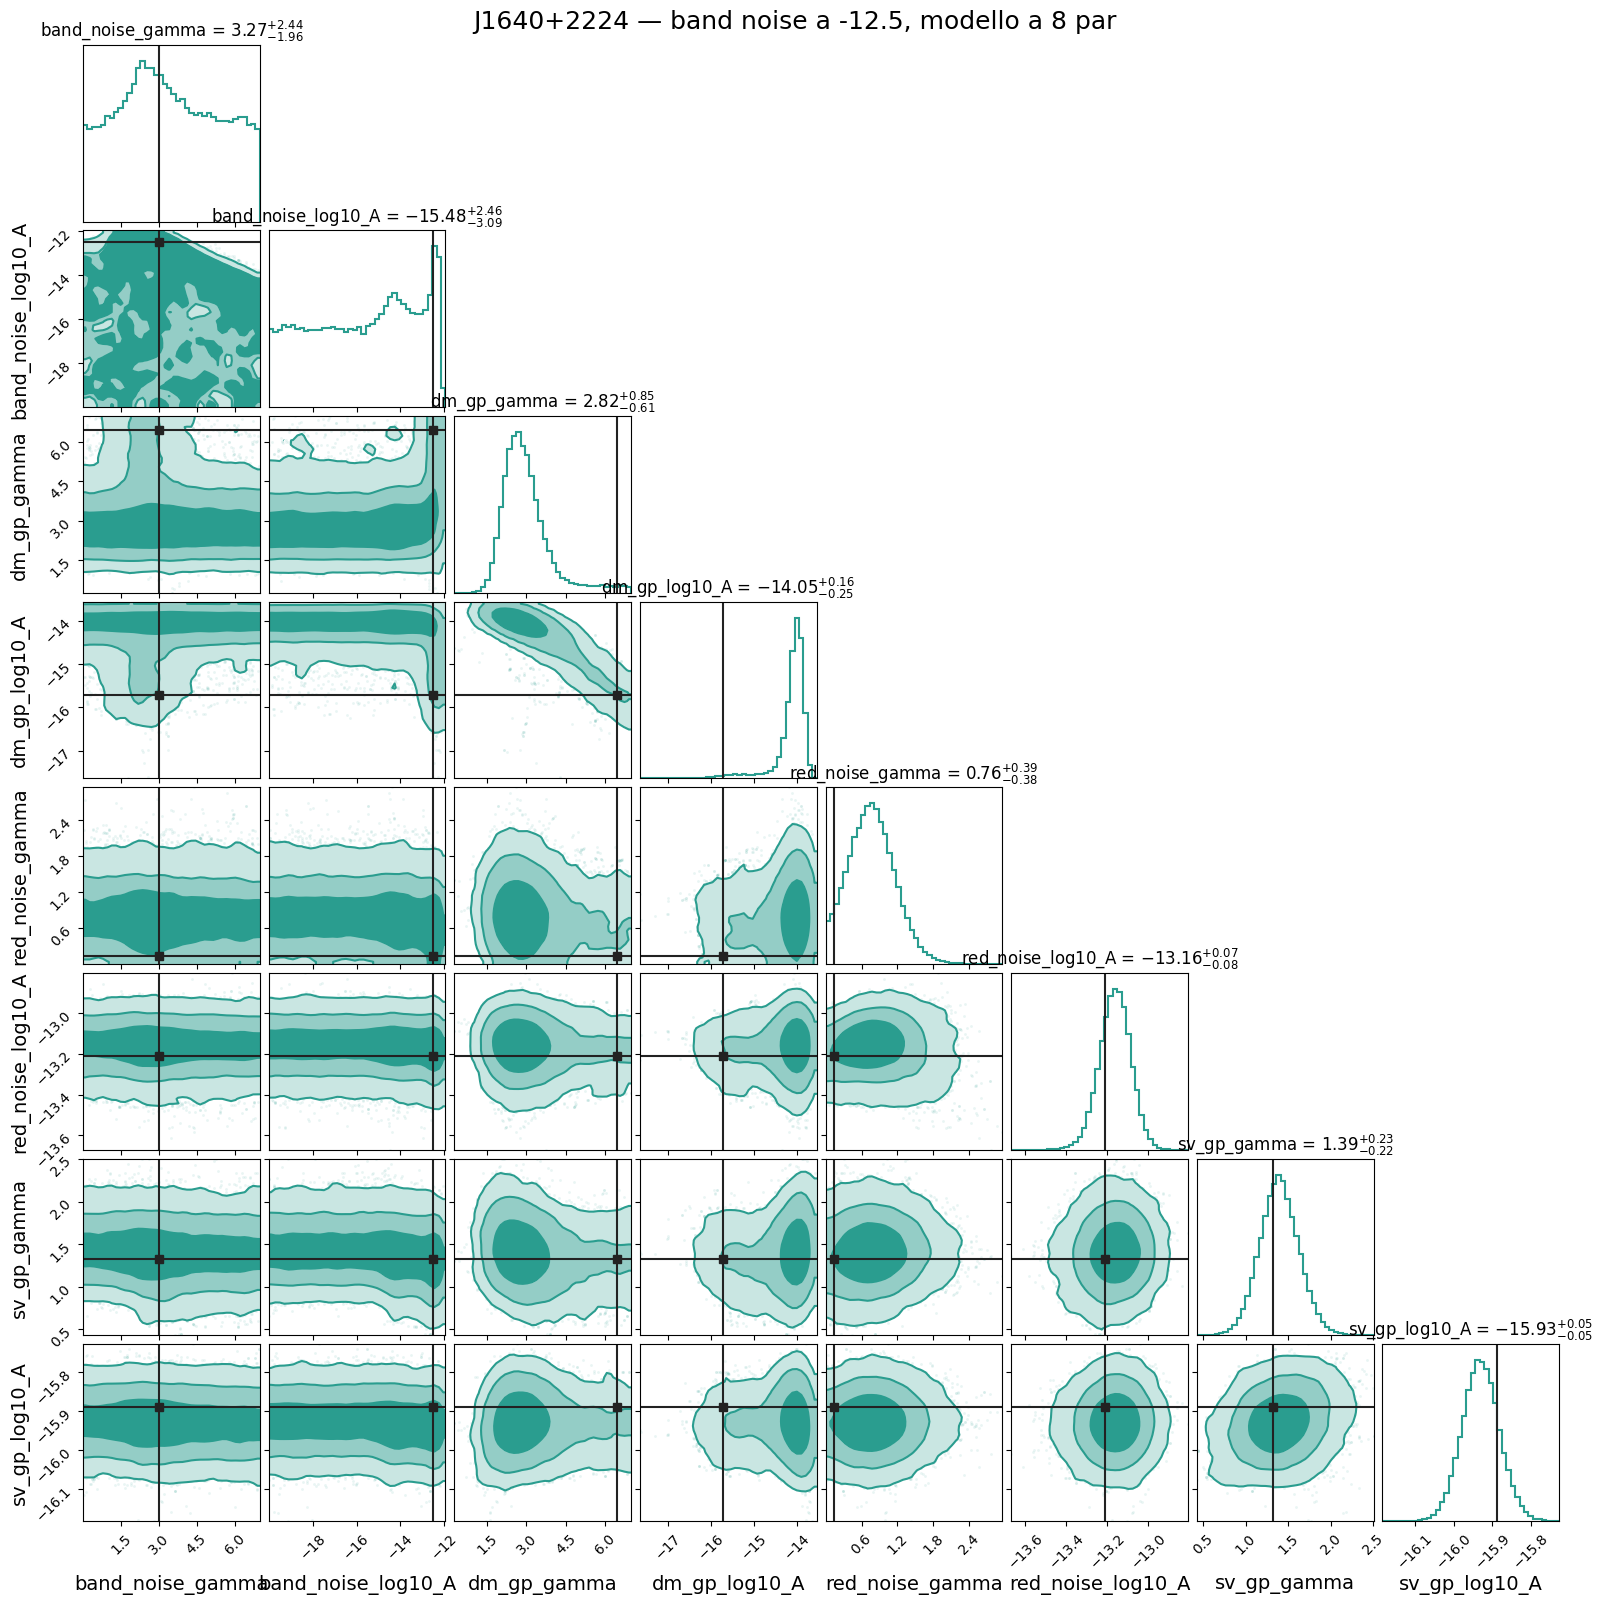

In [29]:
truths_dict = {
    'J1640+2224_dm_gp_gamma': 6.471070651479037,
    'J1640+2224_dm_gp_log10_A': -15.7227863246785,
    'J1640+2224_red_noise_gamma': 0.13235259553929019,
    'J1640+2224_red_noise_log10_A': -13.212902548624186,
    'J1640+2224_sv_gp_gamma': 1.3259815720503758,
    'J1640+2224_sv_gp_log10_A': -15.888300265911965,
    'J1640+2224_band_noise_gamma': 3.0,
    'J1640+2224_band_noise_log10_A': -12.5,
}
truth_values = [truths_dict[p] for p in logL_bn125_8par.params]
clean_labels = [name.replace('J1640+2224_', '') for name in logL_bn125_8par.params]

fig = corner.corner(
    chain_bn125_8par[:],
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color='#2A9D8F',
    hist_kwargs={'color': '#2A9D8F', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — band noise a -12.5, modello a 8 par',
             fontsize=18, y=1.00)

fig.savefig('corner_sim_bn_A125_bnmodel.png', dpi=150, bbox_inches='tight')

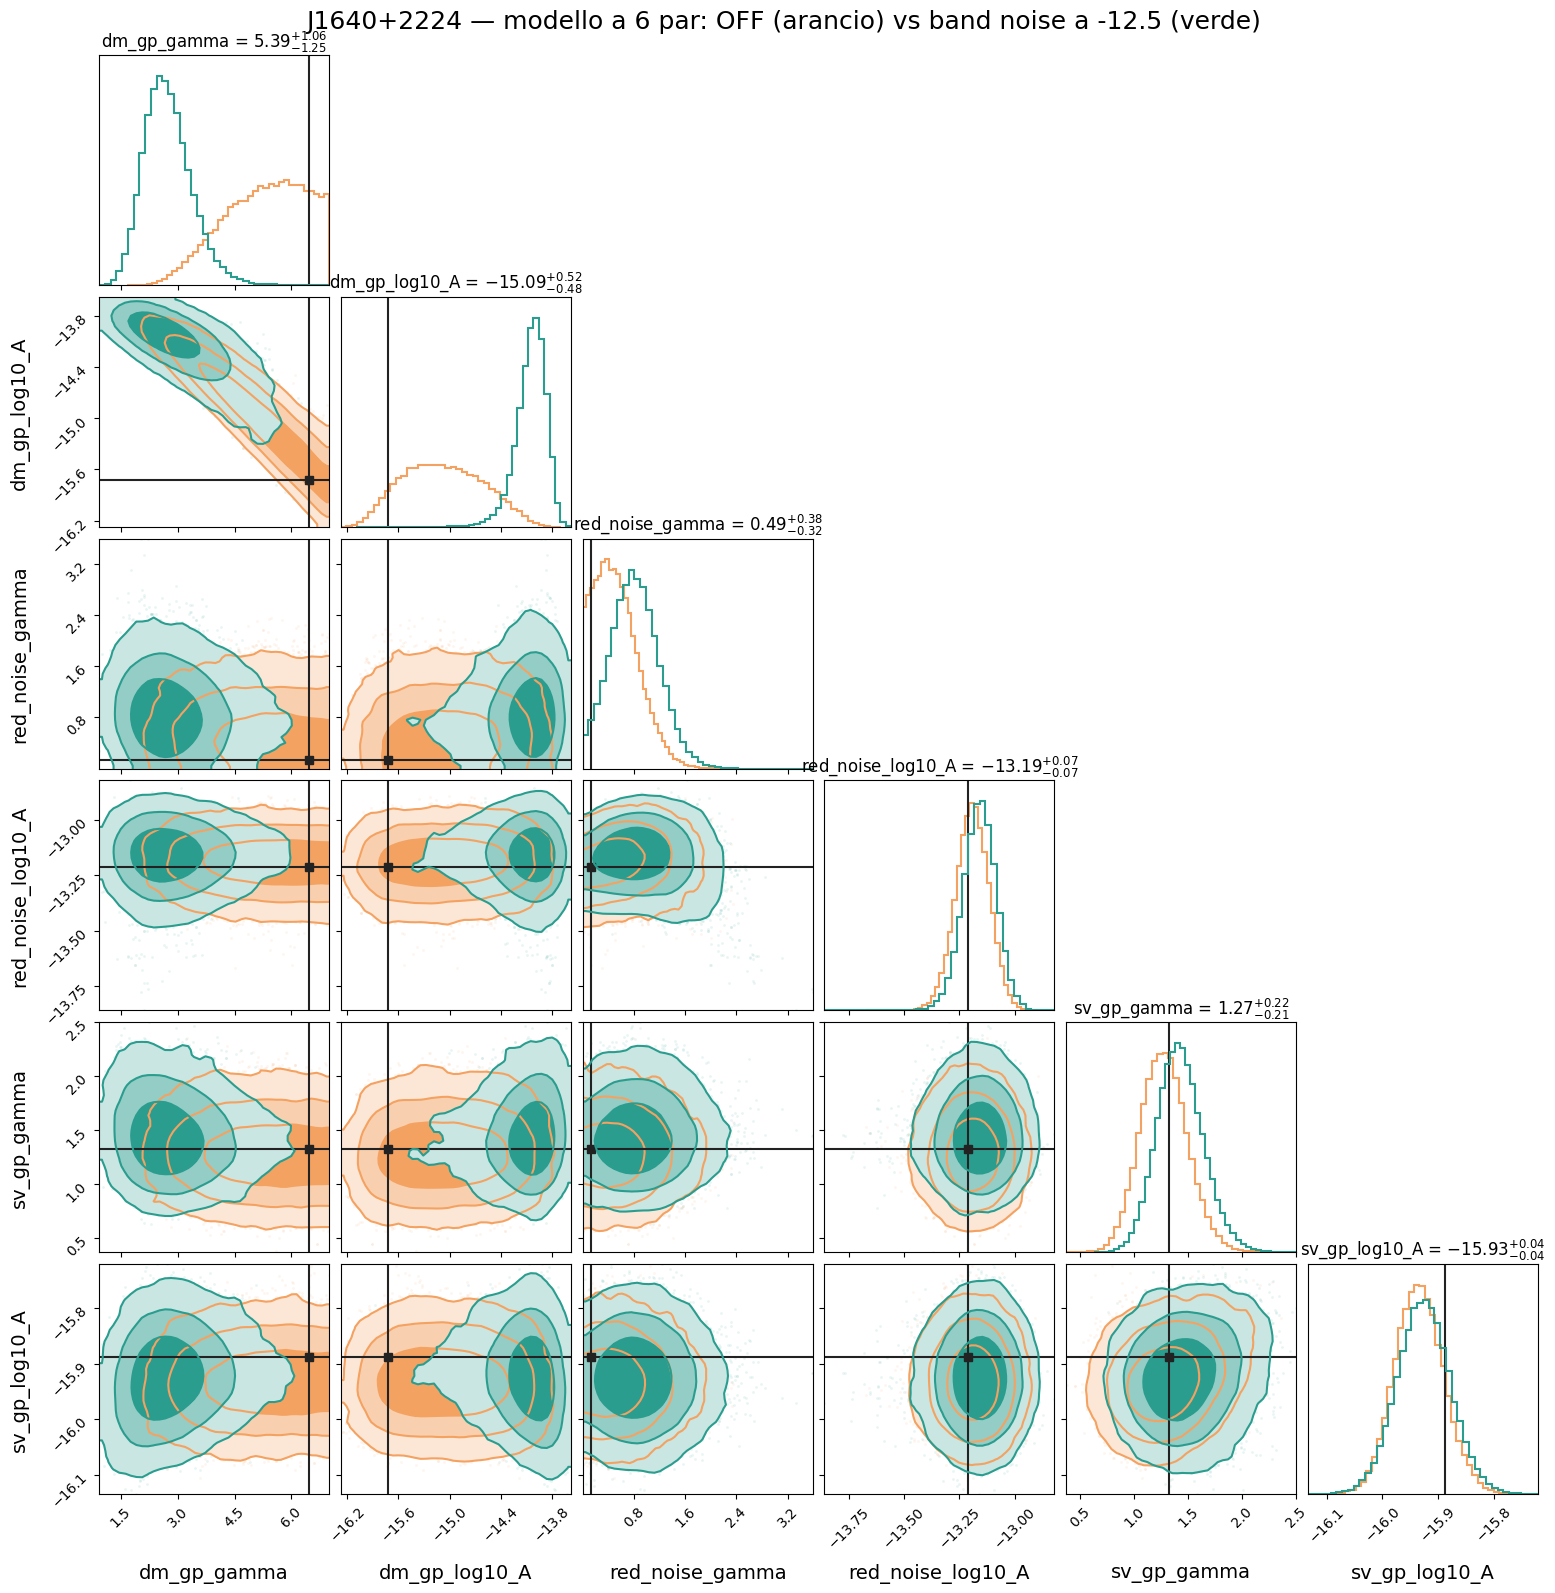

In [53]:
# stesso modello a 6 par, stessa realizzazione: cambia solo il band noise nei dati
truths_dict = {
    'J1640+2224_dm_gp_gamma': 6.471070651479037,
    'J1640+2224_dm_gp_log10_A': -15.7227863246785,
    'J1640+2224_red_noise_gamma': 0.13235259553929019,
    'J1640+2224_red_noise_log10_A': -13.212902548624186,
    'J1640+2224_sv_gp_gamma': 1.3259815720503758,
    'J1640+2224_sv_gp_log10_A': -15.888300265911965,
}
truth_values = [truths_dict[p] for p in logL_bn125_6par.params]
clean_labels = [name.replace('J1640+2224_', '') for name in logL_bn125_6par.params]

# Primo corner
fig = corner.corner(
    chain_off[:],
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color='#F4A261',
    hist_kwargs={'color': '#F4A261', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_bn125_6par[:],
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color='#2A9D8F',
    hist_kwargs={'color': '#2A9D8F', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — modello a 6 par: OFF (arancio) vs band noise a -12.5 (verde)',
             fontsize=18, y=1.00)

fig.savefig('corner_sim_bn_A125_6par_OFF_vs_con.png', dpi=150, bbox_inches='tight')

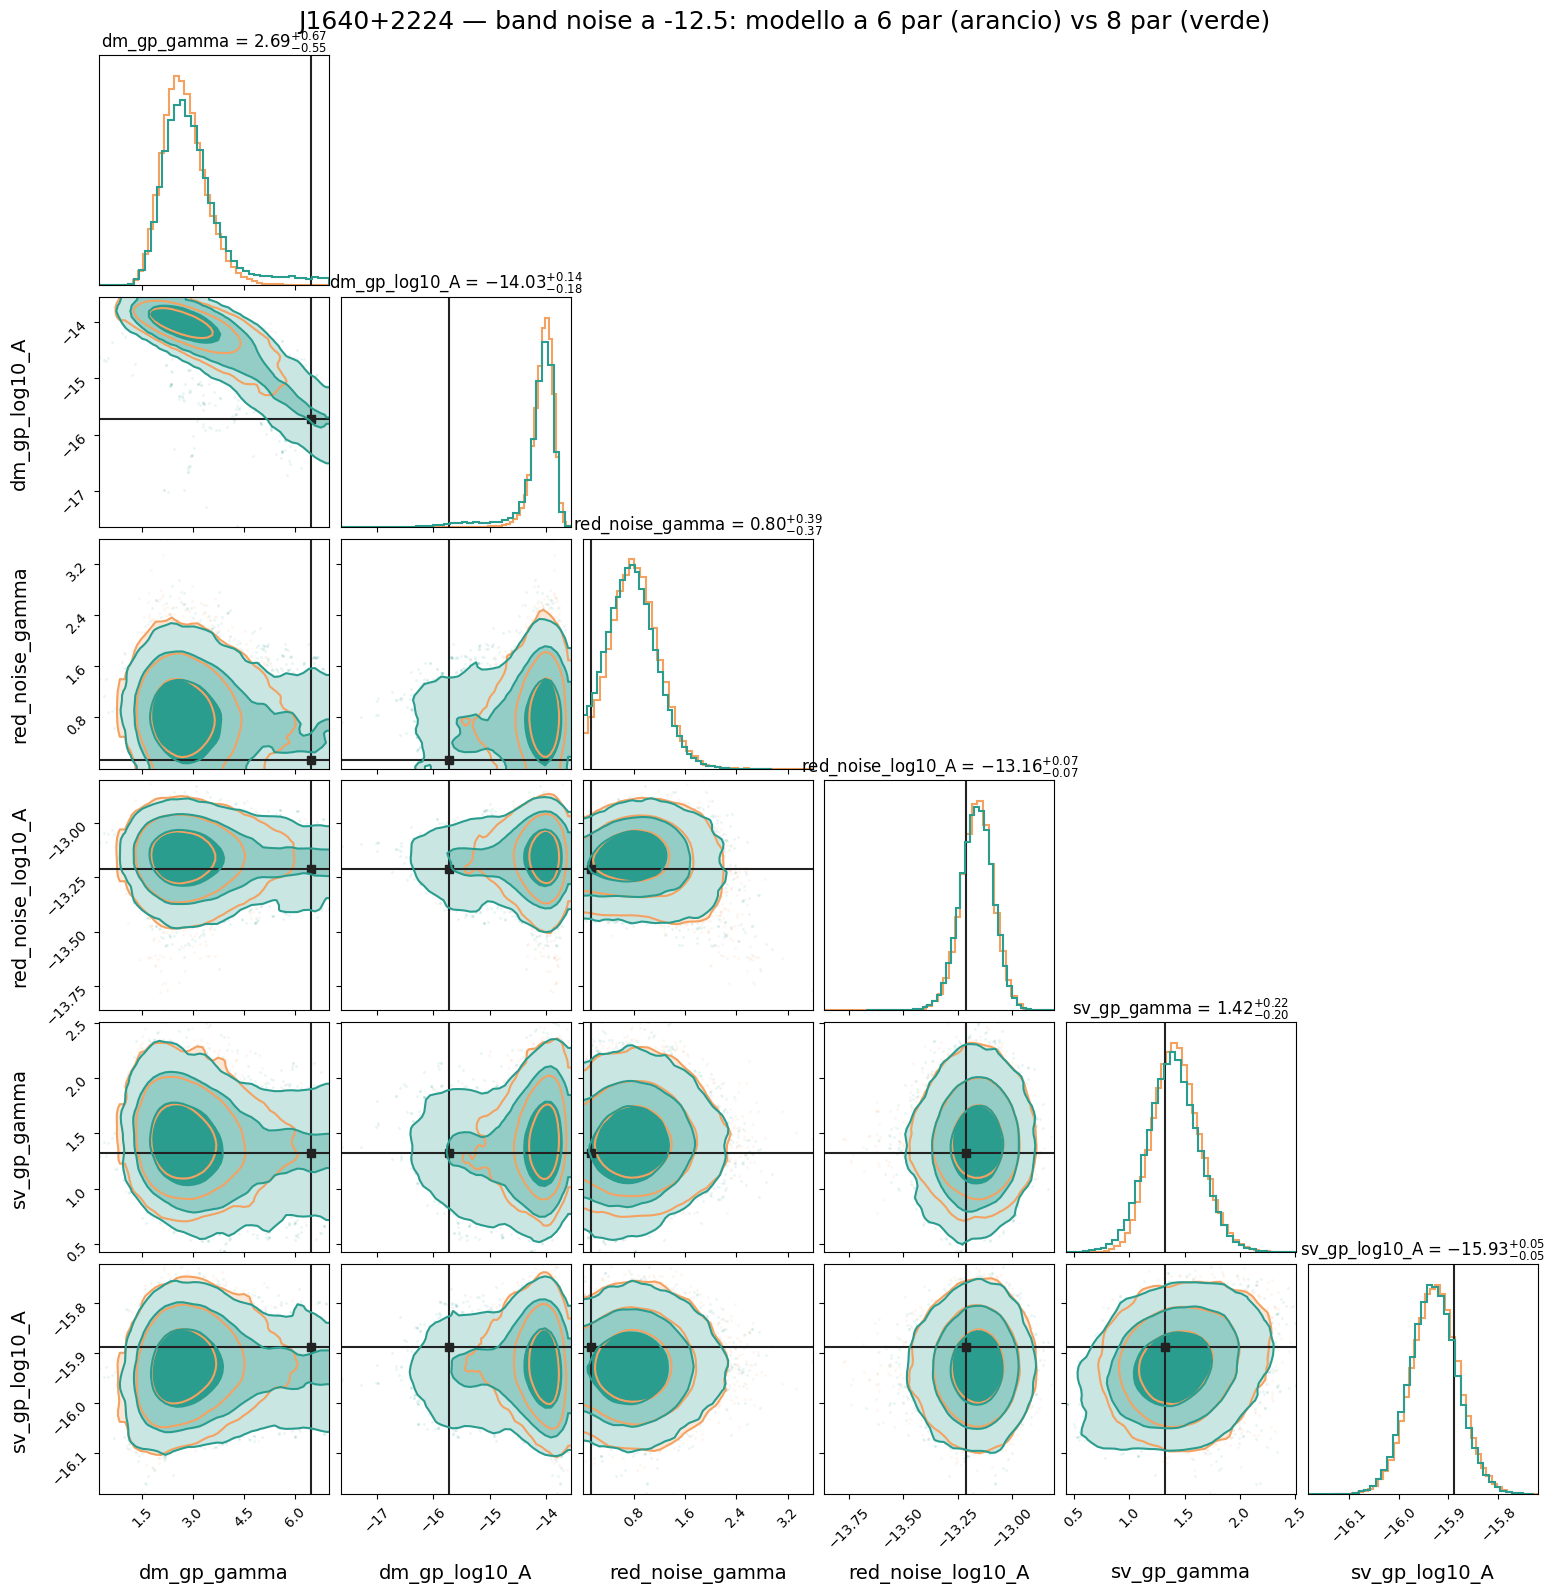

In [54]:
# dalla catena a 8 par tengo solo le 6 colonne comuni, nell ordine del modello a 6 par
chain_bn125_8par_comuni = chain_bn125_8par[:, [list(logL_bn125_8par.params).index(p) for p in logL_bn125_6par.params]]
truths_dict = {
    'J1640+2224_dm_gp_gamma': 6.471070651479037,
    'J1640+2224_dm_gp_log10_A': -15.7227863246785,
    'J1640+2224_red_noise_gamma': 0.13235259553929019,
    'J1640+2224_red_noise_log10_A': -13.212902548624186,
    'J1640+2224_sv_gp_gamma': 1.3259815720503758,
    'J1640+2224_sv_gp_log10_A': -15.888300265911965,
}
truth_values = [truths_dict[p] for p in logL_bn125_6par.params]
clean_labels = [name.replace('J1640+2224_', '') for name in logL_bn125_6par.params]

# Primo corner
fig = corner.corner(
    chain_bn125_6par[:],
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color='#F4A261',
    hist_kwargs={'color': '#F4A261', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_bn125_8par_comuni,
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color='#2A9D8F',
    hist_kwargs={'color': '#2A9D8F', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — band noise a -12.5: modello a 6 par (arancio) vs 8 par (verde)',
             fontsize=18, y=1.00)

fig.savefig('corner_sim_bn_A125_6par_vs_8par.png', dpi=150, bbox_inches='tight')

## A120: band noise a log10_A = -12.0

In [33]:
bn120_psr = ds.pulsar.Pulsar.read_feather('sim_data_noise_bn_A120_sv44_50componenti/J1640+2224')   # band noise a -12.0
print('nome     :', bn120_psr.name)
print('N_TOA    :', len(bn120_psr.toas))
print('shape M  :', bn120_psr.Mmat.shape)

nome     : J1640+2224
N_TOA    : 6777
shape M  : (6777, 39)


### A120, modello a 6 par

In [34]:
# modello a 6 par: quello standard, senza band noise
model_bn120_6par = [bn120_psr.residuals]
model_bn120_6par += [ds.makegp_timing(bn120_psr, svd=True)]
model_bn120_6par += [ds.makenoise_measurement(bn120_psr, bn120_psr.noisedict, tnequad=True, ecorr=True)]
model_bn120_6par.append(ds.makegp_fourier(bn120_psr, ds.powerlaw, bn120_psr.noisedict[bn120_psr.name + '_red_components'],
                                 T=ds.getspan(bn120_psr), name='red_noise'))
model_bn120_6par.append(ds.makegp_fourier(bn120_psr, ds.powerlaw, bn120_psr.noisedict[bn120_psr.name + '_dm_components'],
                                 T=ds.getspan(bn120_psr), name='dm_gp',
                                 fourierbasis=ds.make_dmfourierbasis(alpha=2.0, tndm=False)))
model_bn120_6par.append(ds.makegp_fourier(bn120_psr, ds.powerlaw, bn120_psr.noisedict[bn120_psr.name + '_chrom_components'],
                                 T=ds.getspan(bn120_psr), name='sv_gp',
                                 fourierbasis=ds.make_dmfourierbasis(alpha=4.4, tndm=False)))

logL_bn120_6par = ds.PulsarLikelihood(model_bn120_6par).logL
logL_bn120_6par.params

['J1640+2224_dm_gp_gamma',
 'J1640+2224_dm_gp_log10_A',
 'J1640+2224_red_noise_gamma',
 'J1640+2224_red_noise_log10_A',
 'J1640+2224_sv_gp_gamma',
 'J1640+2224_sv_gp_log10_A']

In [35]:
def params_dict_from_array_bn120_6par(x):
    x = np.asarray(x)
    return dict(zip(logL_bn120_6par.params, x))

priors_bn120_6par = build_priors(logL_bn120_6par.params, my_priordict)

def log_prior_bn120_6par(x):
    params = params_dict_from_array_bn120_6par(x)
    logp = 0.0
    for name, value in params.items():
        if name in priors_bn120_6par:
            logp += priors_bn120_6par[name].logpdf(value)
        else:
            logp += -0.5 * np.sum(np.asarray(value)**2)
    return logp

def prior_draw_bn120_6par():
    return np.array([priors_bn120_6par[name].rvs() for name in logL_bn120_6par.params])

x0_bn120_6par = prior_draw_bn120_6par()

In [36]:
@jax.jit
def _jit_logL_bn120_6par(params_array):
    return logL_bn120_6par(dict(zip(logL_bn120_6par.params, params_array)))

def log_likelihood_bn120_6par(x):
    x = np.asarray(x, dtype=np.float64)
    return float(np.array(_jit_logL_bn120_6par(jnp.array(x))))

print('logL iniziale =', log_likelihood_bn120_6par(x0_bn120_6par))

logL iniziale = 67679.24956886731


In [37]:
sampler_bn120_6par = ptmcmc(
    ndim=len(logL_bn120_6par.params),
    logl=log_likelihood_bn120_6par,
    logp=log_prior_bn120_6par,
    cov=np.eye(len(logL_bn120_6par.params)) * 0.001,
    outDir='./test_sim_bn_A120_50comp/',
    resume=True
)

In [38]:
print("Starting sampling (band noise a -12.0, modello a 6 par)...")
sampler_bn120_6par.sample(x0_bn120_6par, Niter=1000000, thin=10)

Starting sampling (band noise a -12.0, modello a 6 par)...
Finished 1.00 percent (1.00 percent of new work) in 16.726524 s Acceptance rate = 0.2152Adding DE jump with weight 20
Finished 100.00 percent (100.00 percent of new work) in 55923.465597 s Acceptance rate = 0.313932
Run Complete


In [39]:
chain_bn120_6par = np.loadtxt('./test_sim_bn_A120_50comp/chain_1.txt')[:, :-4]
chain_bn120_6par = chain_bn120_6par[len(chain_bn120_6par)//4:]
chain_bn120_6par.shape

(75001, 6)

In [40]:
tau_bn120_6par = emcee.autocorr.integrated_time(chain_bn120_6par, has_walkers=False, quiet=True)
print('tau:', tau_bn120_6par)
print('Effective length =', int(len(chain_bn120_6par) / tau_bn120_6par.max()))

tau: [ 5.7262795   4.84019002 18.72932724 21.38103719  5.25551015  3.63199564]
Effective length = 3507


### A120, modello a 8 par

In [41]:
# modello a 8 par: i 6 standard + band noise sui backend LOFAR
model_bn120_8par = [bn120_psr.residuals]
model_bn120_8par += [ds.makegp_timing(bn120_psr, svd=True)]
model_bn120_8par += [ds.makenoise_measurement(bn120_psr, bn120_psr.noisedict, tnequad=True, ecorr=True)]
model_bn120_8par.append(ds.makegp_fourier(bn120_psr, ds.powerlaw, bn120_psr.noisedict[bn120_psr.name + '_red_components'],
                                 T=ds.getspan(bn120_psr), name='red_noise'))
model_bn120_8par.append(ds.makegp_fourier(bn120_psr, ds.powerlaw, bn120_psr.noisedict[bn120_psr.name + '_dm_components'],
                                 T=ds.getspan(bn120_psr), name='dm_gp',
                                 fourierbasis=ds.make_dmfourierbasis(alpha=2.0, tndm=False)))
model_bn120_8par.append(ds.makegp_fourier(bn120_psr, ds.powerlaw, bn120_psr.noisedict[bn120_psr.name + '_chrom_components'],
                                 T=ds.getspan(bn120_psr), name='sv_gp',
                                 fourierbasis=ds.make_dmfourierbasis(alpha=4.4, tndm=False)))
model_bn120_8par.append(ds.makegp_fourier_select(bn120_psr, ds.powerlaw, components=50, T=ds.getspan(bn120_psr),
                                        name='band_noise', selection=ds.lofar_backends))

logL_bn120_8par = ds.PulsarLikelihood(model_bn120_8par).logL
logL_bn120_8par.params

['J1640+2224_band_noise_gamma',
 'J1640+2224_band_noise_log10_A',
 'J1640+2224_dm_gp_gamma',
 'J1640+2224_dm_gp_log10_A',
 'J1640+2224_red_noise_gamma',
 'J1640+2224_red_noise_log10_A',
 'J1640+2224_sv_gp_gamma',
 'J1640+2224_sv_gp_log10_A']

In [42]:
def params_dict_from_array_bn120_8par(x):
    x = np.asarray(x)
    return dict(zip(logL_bn120_8par.params, x))

priors_bn120_8par = build_priors(logL_bn120_8par.params, my_priordict)

def log_prior_bn120_8par(x):
    params = params_dict_from_array_bn120_8par(x)
    logp = 0.0
    for name, value in params.items():
        if name in priors_bn120_8par:
            logp += priors_bn120_8par[name].logpdf(value)
        else:
            logp += -0.5 * np.sum(np.asarray(value)**2)
    return logp

def prior_draw_bn120_8par():
    return np.array([priors_bn120_8par[name].rvs() for name in logL_bn120_8par.params])

x0_bn120_8par = prior_draw_bn120_8par()

In [44]:
@jax.jit
def _jit_logL_bn120_8par(params_array):
    return logL_bn120_8par(dict(zip(logL_bn120_8par.params, params_array)))

def log_likelihood_bn120_8par(x):
    x = np.asarray(x, dtype=np.float64)
    return float(np.array(_jit_logL_bn120_8par(jnp.array(x))))

print('logL iniziale =', log_likelihood_bn120_8par(x0_bn120_8par))

logL iniziale = 68045.40255416956


In [45]:
sampler_bn120_8par = ptmcmc(
    ndim=len(logL_bn120_8par.params),
    logl=log_likelihood_bn120_8par,
    logp=log_prior_bn120_8par,
    cov=np.eye(len(logL_bn120_8par.params)) * 0.001,
    outDir='./test_sim_bn_A120_bnmodel/',
    resume=True
)

In [46]:
print("Starting sampling (band noise a -12.0, modello a 8 par)...")
sampler_bn120_8par.sample(x0_bn120_8par, Niter=1000000, thin=10)

Starting sampling (band noise a -12.0, modello a 8 par)...
Finished 1.00 percent (1.00 percent of new work) in 23.539996 s Acceptance rate = 0.2696Adding DE jump with weight 20
Finished 100.00 percent (100.00 percent of new work) in 2228.647154 s Acceptance rate = 0.219337
Run Complete


In [47]:
chain_bn120_8par = np.loadtxt('./test_sim_bn_A120_bnmodel/chain_1.txt')[:, :-4]
chain_bn120_8par = chain_bn120_8par[len(chain_bn120_8par)//4:]
chain_bn120_8par.shape

(75001, 8)

In [48]:
tau_bn120_8par = emcee.autocorr.integrated_time(chain_bn120_8par, has_walkers=False, quiet=True)
print('tau:', tau_bn120_8par)
print('Effective length =', int(len(chain_bn120_8par) / tau_bn120_8par.max()))

tau: [ 30.27100589  36.56722258  27.21069241 149.46365897  29.5504079
   9.65828719  12.44677146  11.20671434]
Effective length = 501


### A120, grafici

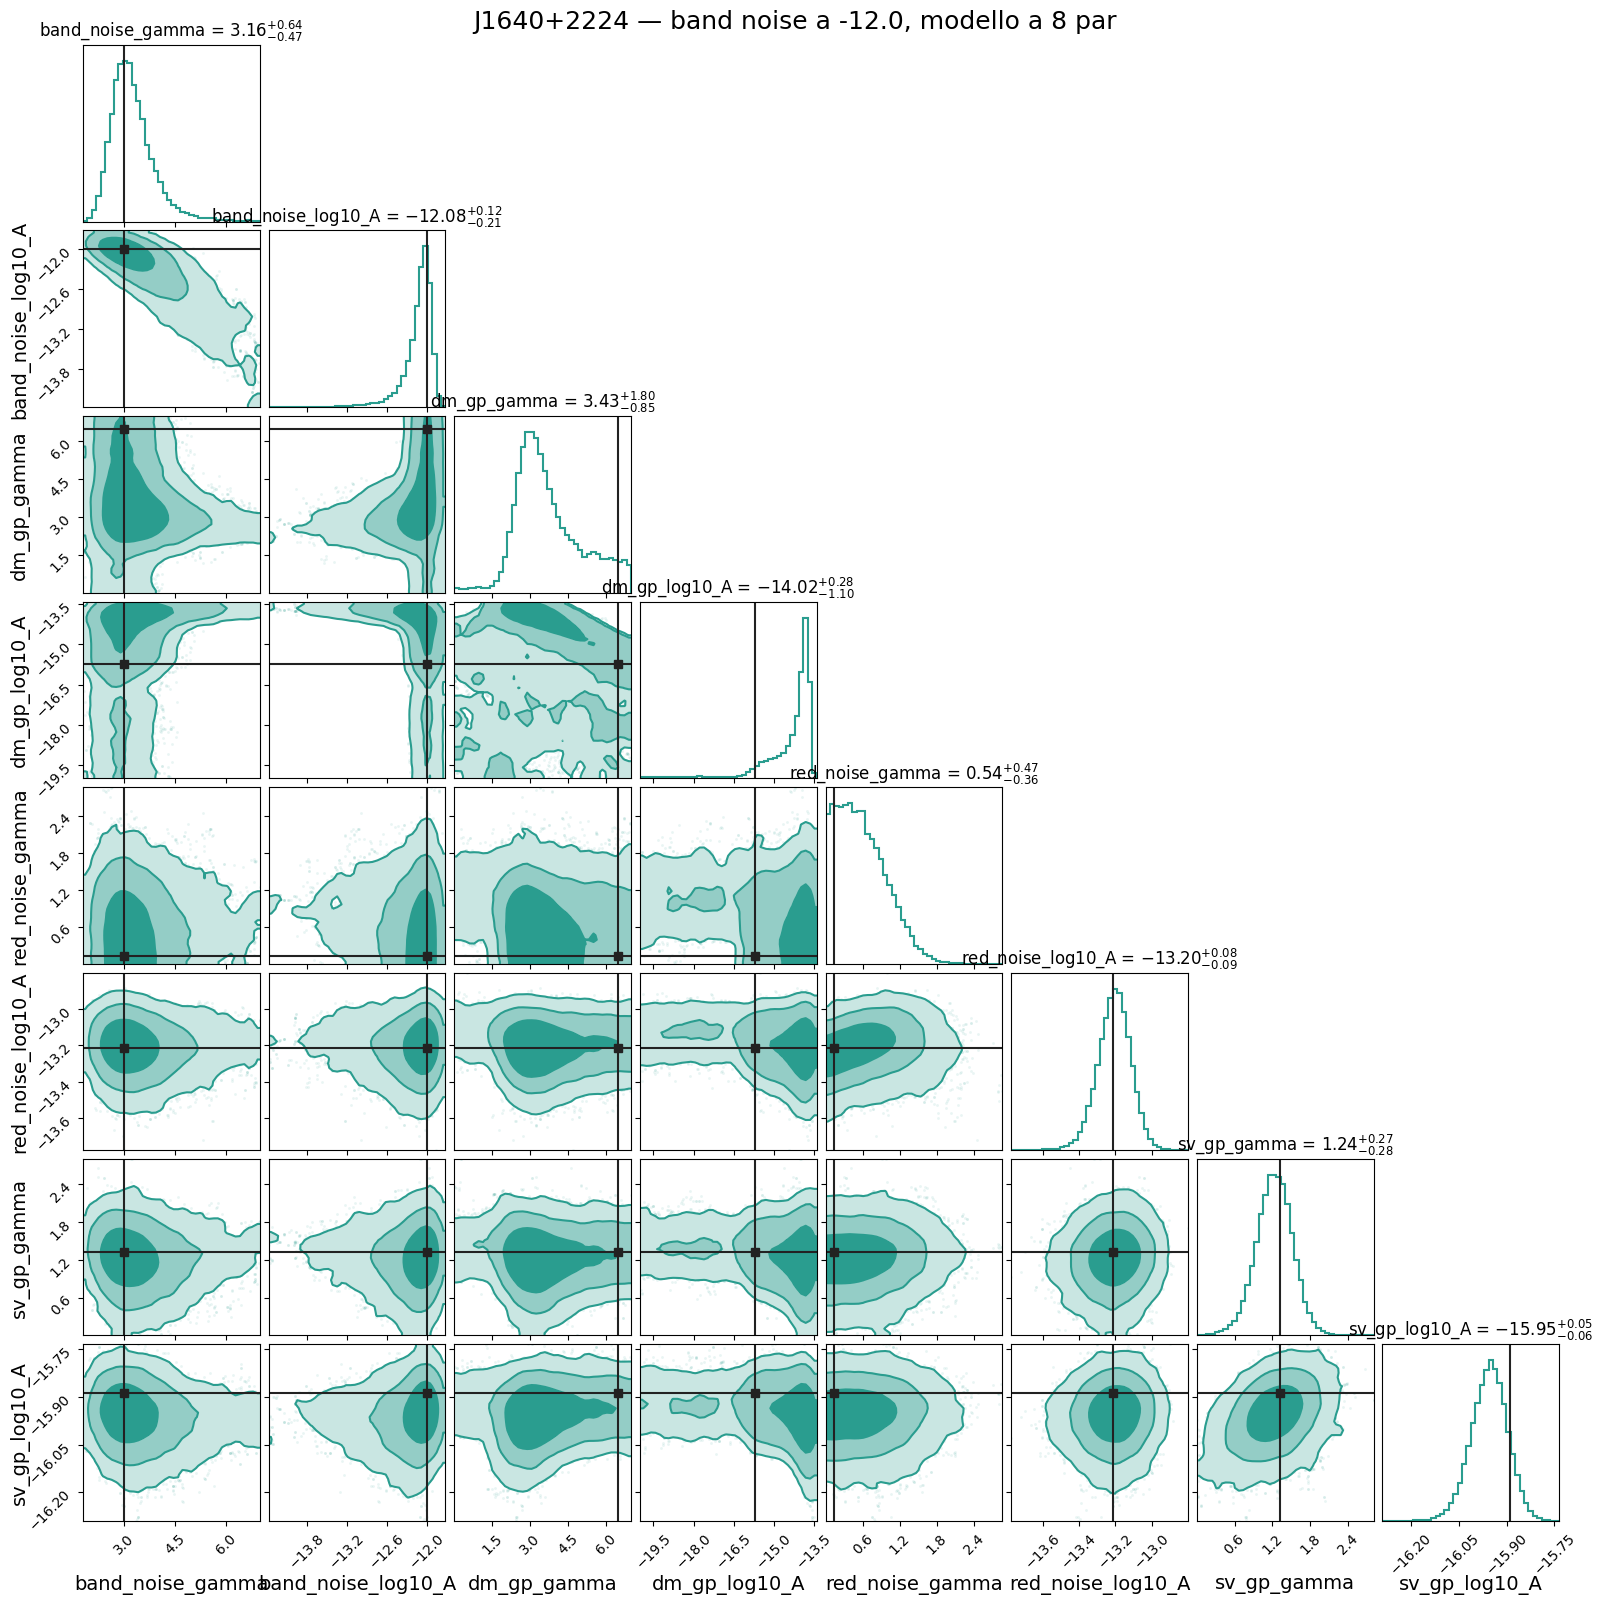

In [49]:
truths_dict = {
    'J1640+2224_dm_gp_gamma': 6.471070651479037,
    'J1640+2224_dm_gp_log10_A': -15.7227863246785,
    'J1640+2224_red_noise_gamma': 0.13235259553929019,
    'J1640+2224_red_noise_log10_A': -13.212902548624186,
    'J1640+2224_sv_gp_gamma': 1.3259815720503758,
    'J1640+2224_sv_gp_log10_A': -15.888300265911965,
    'J1640+2224_band_noise_gamma': 3.0,
    'J1640+2224_band_noise_log10_A': -12.0,
}
truth_values = [truths_dict[p] for p in logL_bn120_8par.params]
clean_labels = [name.replace('J1640+2224_', '') for name in logL_bn120_8par.params]

fig = corner.corner(
    chain_bn120_8par[:],
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color='#2A9D8F',
    hist_kwargs={'color': '#2A9D8F', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — band noise a -12.0, modello a 8 par',
             fontsize=18, y=1.00)

fig.savefig('corner_sim_bn_A120_bnmodel.png', dpi=150, bbox_inches='tight')

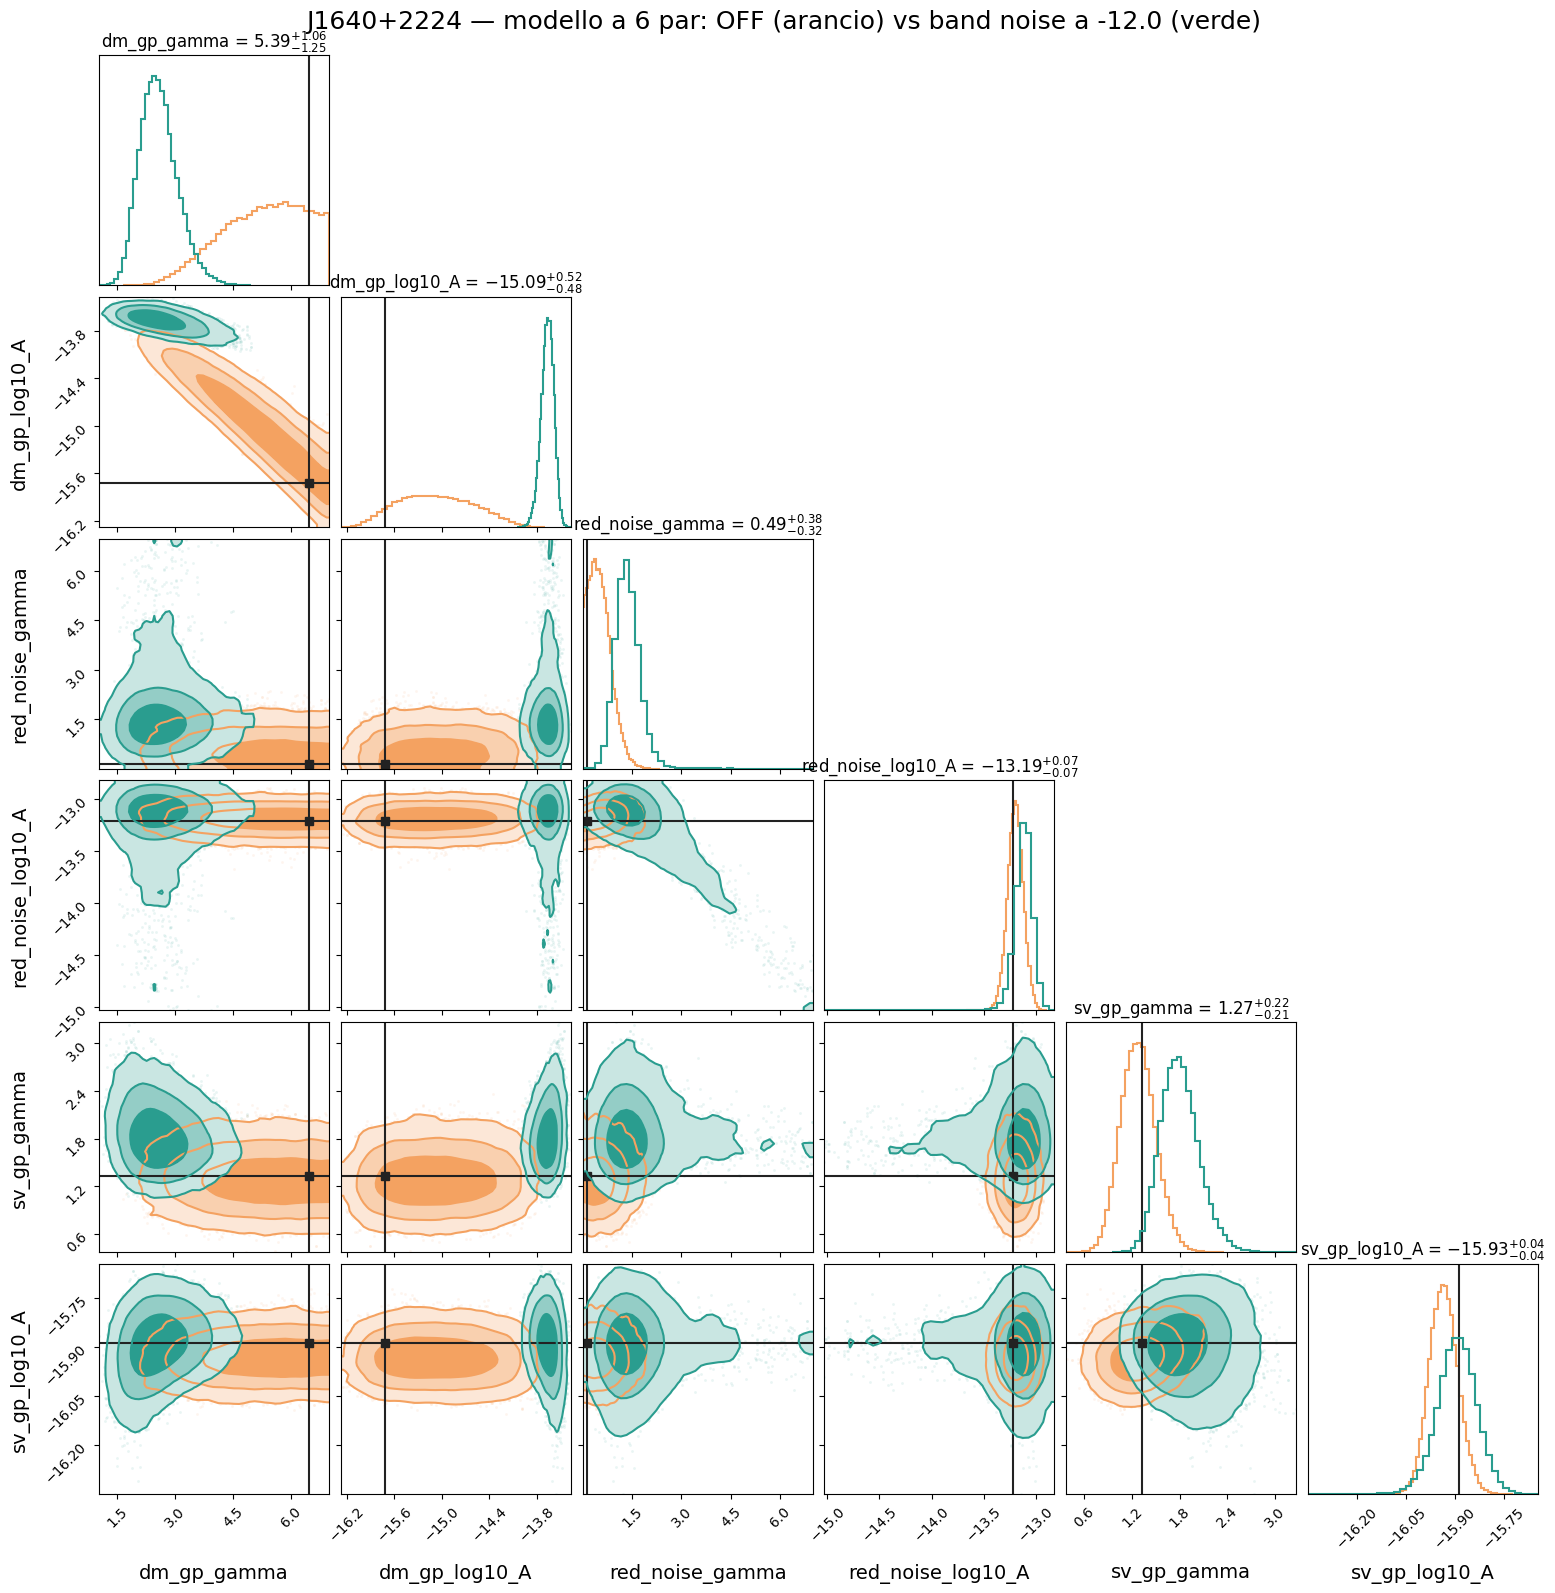

In [55]:
# stesso modello a 6 par, stessa realizzazione: cambia solo il band noise nei dati
truths_dict = {
    'J1640+2224_dm_gp_gamma': 6.471070651479037,
    'J1640+2224_dm_gp_log10_A': -15.7227863246785,
    'J1640+2224_red_noise_gamma': 0.13235259553929019,
    'J1640+2224_red_noise_log10_A': -13.212902548624186,
    'J1640+2224_sv_gp_gamma': 1.3259815720503758,
    'J1640+2224_sv_gp_log10_A': -15.888300265911965,
}
truth_values = [truths_dict[p] for p in logL_bn120_6par.params]
clean_labels = [name.replace('J1640+2224_', '') for name in logL_bn120_6par.params]

# Primo corner
fig = corner.corner(
    chain_off[:],
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color='#F4A261',
    hist_kwargs={'color': '#F4A261', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_bn120_6par[:],
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color='#2A9D8F',
    hist_kwargs={'color': '#2A9D8F', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — modello a 6 par: OFF (arancio) vs band noise a -12.0 (verde)',
             fontsize=18, y=1.00)

fig.savefig('corner_sim_bn_A120_6par_OFF_vs_con.png', dpi=150, bbox_inches='tight')

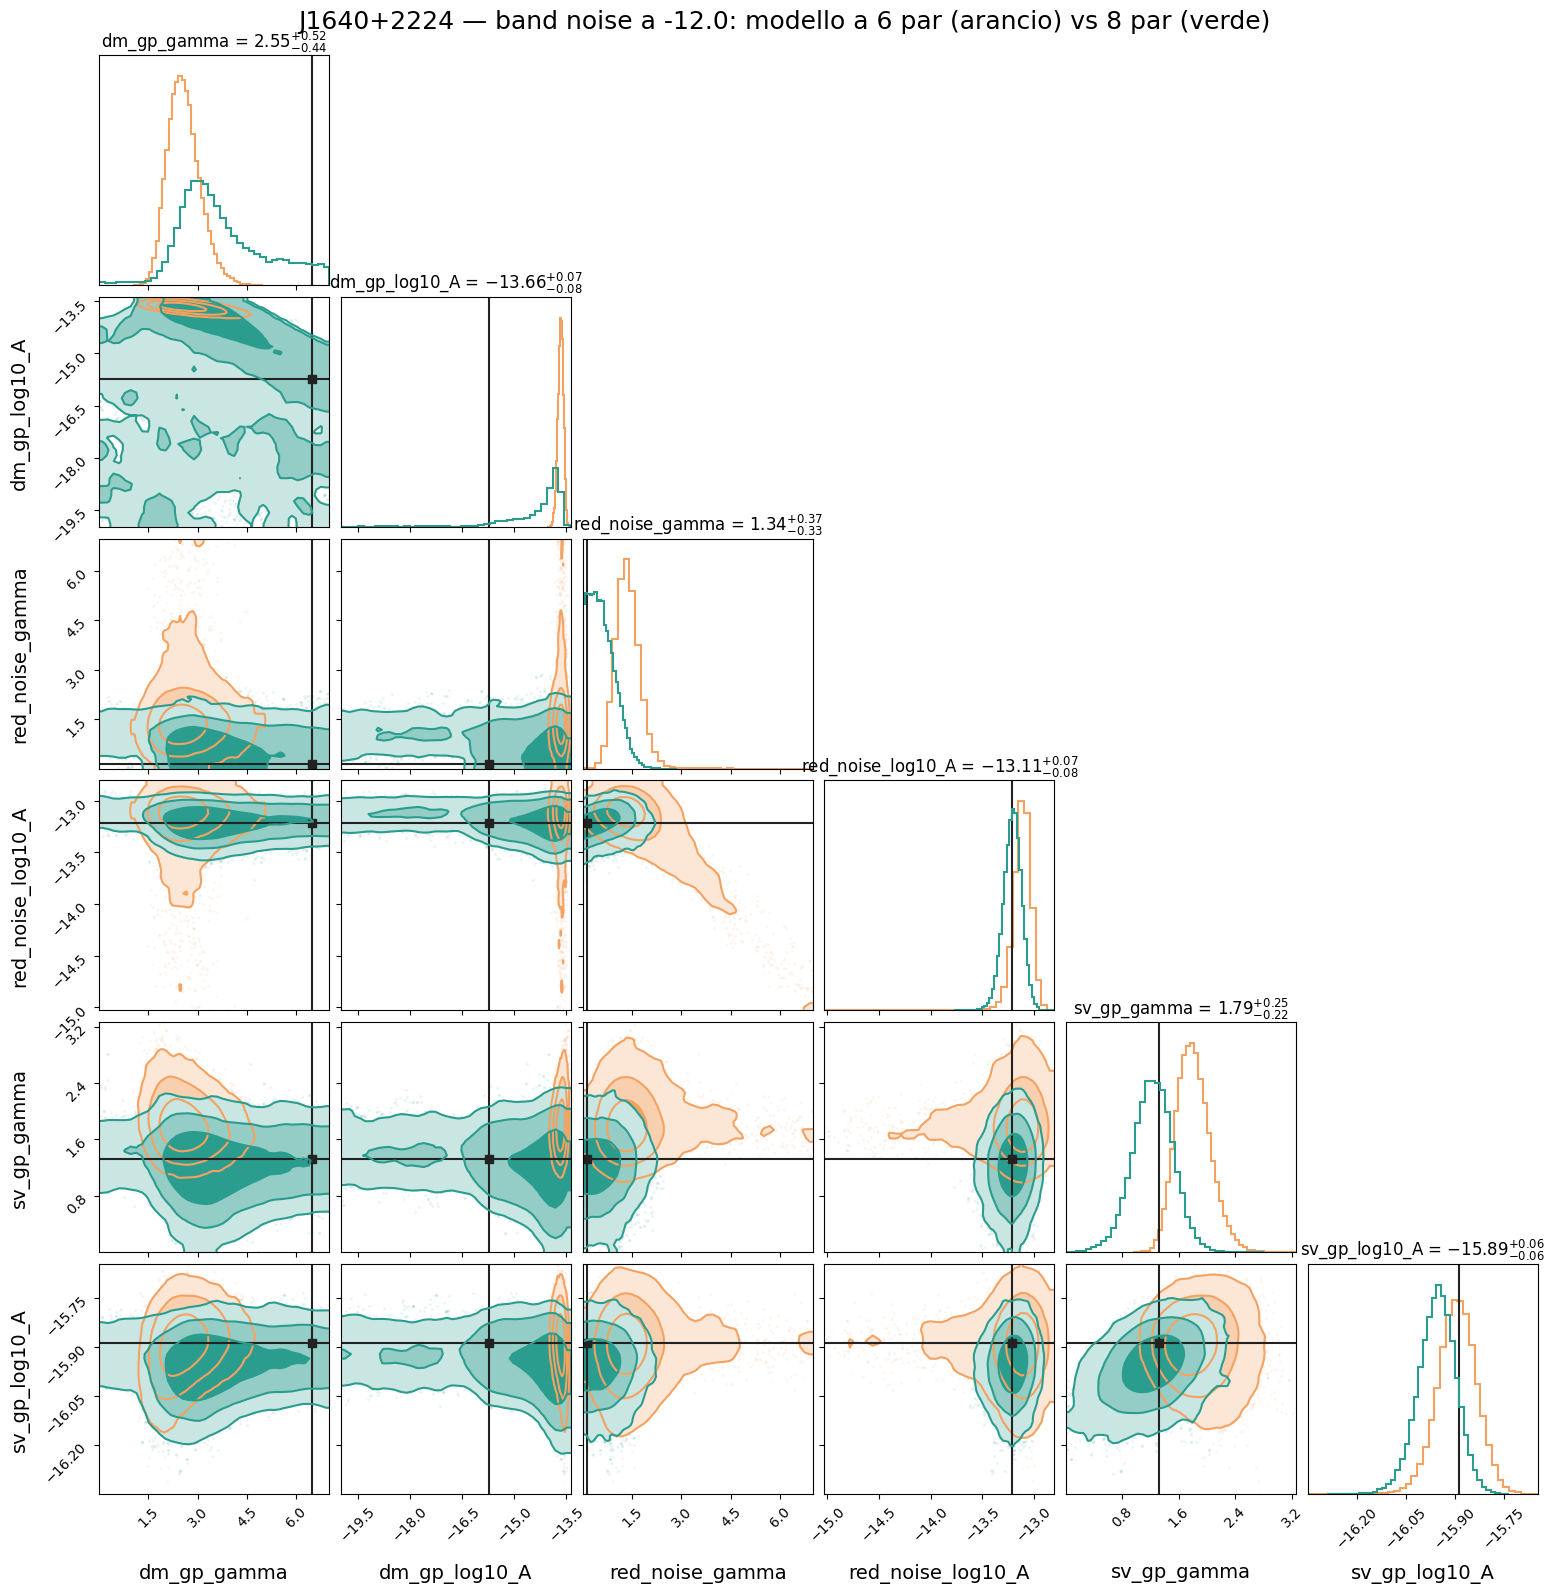

In [56]:
# dalla catena a 8 par tengo solo le 6 colonne comuni, nell ordine del modello a 6 par
chain_bn120_8par_comuni = chain_bn120_8par[:, [list(logL_bn120_8par.params).index(p) for p in logL_bn120_6par.params]]
truths_dict = {
    'J1640+2224_dm_gp_gamma': 6.471070651479037,
    'J1640+2224_dm_gp_log10_A': -15.7227863246785,
    'J1640+2224_red_noise_gamma': 0.13235259553929019,
    'J1640+2224_red_noise_log10_A': -13.212902548624186,
    'J1640+2224_sv_gp_gamma': 1.3259815720503758,
    'J1640+2224_sv_gp_log10_A': -15.888300265911965,
}
truth_values = [truths_dict[p] for p in logL_bn120_6par.params]
clean_labels = [name.replace('J1640+2224_', '') for name in logL_bn120_6par.params]

# Primo corner
fig = corner.corner(
    chain_bn120_6par[:],
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color='#F4A261',
    hist_kwargs={'color': '#F4A261', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_bn120_8par_comuni,
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color='#2A9D8F',
    hist_kwargs={'color': '#2A9D8F', 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — band noise a -12.0: modello a 6 par (arancio) vs 8 par (verde)',
             fontsize=18, y=1.00)

fig.savefig('corner_sim_bn_A120_6par_vs_8par.png', dpi=150, bbox_inches='tight')

## Riepilogo

In [57]:
# modello a 6 par: mediana e intervallo al 68% di ogni parametro, per ogni ampiezza
truths_dict = {
    'J1640+2224_dm_gp_gamma': 6.471070651479037,
    'J1640+2224_dm_gp_log10_A': -15.7227863246785,
    'J1640+2224_red_noise_gamma': 0.13235259553929019,
    'J1640+2224_red_noise_log10_A': -13.212902548624186,
    'J1640+2224_sv_gp_gamma': 1.3259815720503758,
    'J1640+2224_sv_gp_log10_A': -15.888300265911965,
}
etichette = ['OFF', '-13', '-12.5', '-12']
catene = [chain_off, chain_bn130_6par, chain_bn125_6par, chain_bn120_6par]

fig, axs = plt.subplots(2, 3, figsize=(15, 8))
for ax, (i, name) in zip(axs.flat, enumerate(logL_off.params)):
    for j, ch in enumerate(catene):
        q16, q50, q84 = np.percentile(ch[:, i], [16, 50, 84])
        ax.errorbar(j, q50, yerr=[[q50 - q16], [q84 - q50]], fmt='o', color='#2A9D8F', capsize=4)
    ax.axhline(truths_dict[name], color='#222222', lw=1)
    ax.set_xticks(range(len(etichette)))
    ax.set_xticklabels(etichette)
    ax.set_title(name.replace('J1640+2224_', ''), fontsize=12)
    ax.grid(alpha=0.25, linestyle='--')

fig.suptitle('Modello a 6 par: parametri in funzione del band noise iniettato', fontsize=15)
fig.tight_layout()
fig.savefig('riepilogo_bn_6par_vs_ampiezza.png', dpi=150, bbox_inches='tight')

NameError: name 'chain_bn130_6par' is not defined

In [58]:
# modello a 8 par: posteriore dell ampiezza del band noise per le tre ampiezze
plt.figure(figsize=(8, 4.5))
for ch, logL_run, amp, colore in [(chain_bn130_8par, logL_bn130_8par, -13.0, '#F4A261'),
                                  (chain_bn125_8par, logL_bn125_8par, -12.5, '#2A9D8F'),
                                  (chain_bn120_8par, logL_bn120_8par, -12.0, '#6A4C93')]:
    i = list(logL_run.params).index('J1640+2224_band_noise_log10_A')
    plt.hist(ch[:, i], bins=60, range=(-20, -11), density=True, histtype='step', lw=1.8, color=colore,
             label=f'iniettato a {amp}')
    plt.axvline(amp, color=colore, ls='--', lw=1.2)
plt.xlabel('band_noise_log10_A')
plt.ylabel('densita')
plt.legend(frameon=False)
plt.grid(alpha=0.25, linestyle='--')
plt.savefig('riepilogo_bn_8par_recupero.png', dpi=150, bbox_inches='tight')

NameError: name 'chain_bn130_8par' is not defined

<Figure size 800x450 with 0 Axes>